In [1]:

!pip -q install gdown

import gdown

file_id = "1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49"
url = f"https://drive.google.com/uc?id={file_id}"

output_file = "/content/Nassau Candy Distributor.csv"

result = gdown.download(url, output_file, quiet=False)

if result is None:
    raise RuntimeError("Download failed. Check the Google Drive link permissions.")

print("Dataset downloaded successfully!")


Downloading...
From: https://drive.google.com/uc?id=1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49
To: /content/Nassau Candy Distributor.csv
100%|██████████| 1.98M/1.98M [00:00<00:00, 73.4MB/s]

Dataset downloaded successfully!


In [2]:

!pip -q install gdown

import gdown
import pandas as pd
import numpy as np

file_id = "1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49"
url = f"https://drive.google.com/uc?id={file_id}"

file_path = "/content/Nassau Candy Distributor.csv"
gdown.download(url, file_path, quiet=False)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Downloading...
From: https://drive.google.com/uc?id=1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49
To: /content/Nassau Candy Distributor.csv
100%|██████████| 1.98M/1.98M [00:00<00:00, 48.9MB/s]

Dataset loaded successfully!
Number of rows: 10194
Number of columns: 18


In [3]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

print("ORDER DATE RANGE")
print("Earliest:", df["Order Date"].min())
print("Latest:", df["Order Date"].max())

print("\nSHIP DATE RANGE")
print("Earliest:", df["Ship Date"].min())
print("Latest:", df["Ship Date"].max())

print("\nINVALID ORDER DATES:", df["Order Date"].isna().sum())
print("INVALID SHIP DATES:", df["Ship Date"].isna().sum())


ORDER DATE RANGE
Earliest: 2024-01-02 00:00:00
Latest: 2025-12-31 00:00:00

SHIP DATE RANGE
Earliest: 2026-06-30 00:00:00
Latest: 2030-06-28 00:00:00

INVALID ORDER DATES: 0
INVALID SHIP DATES: 0


In [4]:

df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("FIRST 10 ORDERS")
display(
    df[[
        "Order Date",
        "Ship Date",
        "Ship Mode",
        "Shipping Lead Time"
    ]].head(10)
)

print("\nLEAD TIME STATISTICS")
print(df["Shipping Lead Time"].describe())

print("\nLEAD TIME BY SHIPPING MODE")
display(
    df.groupby("Ship Mode")["Shipping Lead Time"]
      .agg(["count", "mean", "min", "max"])
      .round(2)
)

print("\nORDER COUNTS BY YEAR")
print(df["Order Date"].dt.year.value_counts().sort_index())

print("\nSHIP COUNTS BY YEAR")
print(df["Ship Date"].dt.year.value_counts().sort_index())


FIRST 10 ORDERS


,Order Date,Ship Date,Ship Mode,Shipping Lead Time
0,2024-01-03,2026-06-30,Standard Class,909
1,2024-01-04,2026-07-01,Standard Class,909
2,2024-01-04,2026-07-01,Standard Class,909
3,2024-01-04,2026-07-01,Standard Class,909
4,2024-01-05,2026-07-05,Standard Class,912
5,2024-01-06,2026-07-03,Standard Class,909
6,2024-01-06,2026-07-03,Standard Class,909
7,2024-01-06,2026-06-30,First Class,906
8,2024-01-06,2026-07-03,Standard Class,909
9,2024-01-06,2026-07-03,Standard Class,909



LEAD TIME STATISTICS
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64

LEAD TIME BY SHIPPING MODE


,count,mean,min,max
Ship Mode,,,,
First Class,1548,1338.28,905,1638
Same Day,547,1333.44,904,1636
Second Class,1979,1323.85,906,1640
Standard Class,6120,1314.33,908,1642



ORDER COUNTS BY YEAR
Order Date
2024    4181
2025    6013
Name: count, dtype: int64

SHIP COUNTS BY YEAR
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64


In [5]:

print("ORDERS PER YEAR")
print(
    df["Order Date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nSHIPMENTS PER YEAR")
print(
    df["Ship Date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nMOST COMMON LEAD TIMES")
print(
    df["Shipping Lead Time"]
    .value_counts()
    .head(10)
    .to_string()
)


ORDERS PER YEAR
Order Date
2024    4181
2025    6013

SHIPMENTS PER YEAR
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128

MOST COMMON LEAD TIMES
Shipping Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449


In [6]:

print("SAMPLE DATE COMPARISON")

display(
    df[["Order ID", "Order Date", "Ship Date", "Shipping Lead Time"]]
    .sample(15, random_state=42)
    .sort_values("Order Date")
)

print("\nDATE DIFFERENCES IN DAYS")
print(
    (df["Ship Date"] - df["Order Date"])
    .dt.days
    .describe()
)
print("\nUNIQUE ORDER DATES:", df["Order Date"].nunique())
print("UNIQUE SHIP DATES:", df["Ship Date"].nunique())


SAMPLE DATE COMPARISON


,Order ID,Order Date,Ship Date,Shipping Lead Time
2876,US-2022-120810-CHO-SCR-58000,2024-07-23,2028-01-17,1273
3149,US-2022-165057-CHO-FUD-51000,2024-09-11,2028-03-07,1273
3742,US-2022-102778-CHO-TRI-54000,2024-11-21,2028-05-16,1272
1780,CA-2021-123664-CHO-MIL-31000,2024-12-02,2027-05-29,908
4165,US-2022-135580-CHO-SCR-58000,2024-12-30,2028-06-25,1273
7742,US-2024-132297-CHO-FUD-51000,2025-05-27,2029-11-23,1641
5114,US-2023-153577-CHO-TRI-54000,2025-06-27,2028-12-21,1273
8390,US-2024-119011-CHO-TRI-54000,2025-08-20,2030-02-15,1640
5610,US-2023-151372-CHO-NUT-13000,2025-09-05,2029-02-26,1270
8970,US-2024-126074-CHO-SCR-58000,2025-10-02,2030-03-29,1639



DATE DIFFERENCES IN DAYS
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

UNIQUE ORDER DATES: 717
UNIQUE SHIP DATES: 1338


In [7]:

print("MOST COMMON LEAD TIMES")
print(
    df["Shipping Lead Time"]
      .value_counts()
      .head(15)
      .to_string()
)

print("\nORDER DATE AND SHIP DATE CORRELATION")
print(
    df["Order Date"].astype("int64").corr(
        df["Ship Date"].astype("int64")
    )
)

print("\nAVERAGE LEAD TIME BY ORDER YEAR")
display(
    df.groupby(df["Order Date"].dt.year)["Shipping Lead Time"]
      .agg(["count", "mean", "min", "max"])
      .round(2)
)


MOST COMMON LEAD TIMES
Shipping Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258

ORDER DATE AND SHIP DATE CORRELATION
0.8744237951380949

AVERAGE LEAD TIME BY ORDER YEAR


,count,mean,min,max
Order Date,,,,
2024,4181,1094.02,904,1277
2025,6013,1478.56,1269,1642


In [8]:

display(
    df[[
        "Order ID",
        "Order Date",
        "Ship Date",
        "Ship Mode",
        "Shipping Lead Time"
    ]].sort_values("Order Date").head(20)
)

print("\nLEAD TIME COUNTS BY ORDER YEAR")

display(
    df.groupby(df["Order Date"].dt.year)["Shipping Lead Time"]
      .value_counts()
      .groupby(level=0)
      .head(5)
      .rename("Frequency")
      .reset_index()
)

,Order ID,Order Date,Ship Date,Ship Mode,Shipping Lead Time
2057,US-2022-146262-CHO-MIL-31000,2024-01-02,2027-07-02,Standard Class,1277
2058,US-2022-146262-CHO-TRI-54000,2024-01-02,2027-07-02,Standard Class,1277
2056,US-2022-146262-CHO-NUT-13000,2024-01-02,2027-07-02,Standard Class,1277
2055,US-2022-104514-CHO-MIL-31000,2024-01-02,2027-06-27,Second Class,1272
2054,US-2022-104514-CHO-SCR-58000,2024-01-02,2027-06-27,Second Class,1272
2053,US-2022-146262-CHO-FUD-51000,2024-01-02,2027-07-02,Standard Class,1277
2052,US-2022-104514-CHO-MIL-31000,2024-01-02,2027-06-27,Second Class,1272
2051,US-2022-146262-CHO-NUT-13000,2024-01-02,2027-07-02,Standard Class,1277
2062,US-2022-141243-CHO-NUT-13000,2024-01-03,2027-07-01,Second Class,1275
2061,US-2022-121097-CHO-MIL-31000,2024-01-03,2027-07-01,Standard Class,1275



LEAD TIME COUNTS BY ORDER YEAR


,Order Date,Shipping Lead Time,Frequency
0,2024,1273,624
1,2024,908,591
2,2024,909,519
3,2024,1274,469
4,2024,906,289
5,2025,1639,896
6,2025,1273,702
7,2025,1640,657
8,2025,1274,566
9,2025,1637,449


In [9]:
import pandas as pd

raw_df = pd.read_csv("/content/Nassau Candy Distributor.csv")

print("ORIGINAL CSV DATE VALUES")
display(raw_df[["Order ID", "Order Date", "Ship Date"]].head(15))

print("\nORIGINAL DATE FORMATS")
print("Order Date examples:", raw_df["Order Date"].dropna().unique()[:10])
print("Ship Date examples:", raw_df["Ship Date"].dropna().unique()[:10])

ORIGINAL CSV DATE VALUES


,Order ID,Order Date,Ship Date
0,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026
1,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026
2,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026
3,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026
4,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026
5,US-2021-167199-CHO-SCR-58000,06-01-2024,03-07-2026
6,US-2021-167199-CHO-TRI-54000,06-01-2024,03-07-2026
7,US-2021-106054-CHO-MIL-31000,06-01-2024,30-06-2026
8,US-2021-167199-CHO-NUT-13000,06-01-2024,03-07-2026
9,US-2021-167199-CHO-MIL-31000,06-01-2024,03-07-2026



ORIGINAL DATE FORMATS
Order Date examples: ['03-01-2024' '04-01-2024' '05-01-2024' '06-01-2024' '07-01-2024'
 '09-01-2024' '10-01-2024' '11-01-2024' '13-01-2024' '14-01-2024']
Ship Date examples: ['30-06-2026' '01-07-2026' '05-07-2026' '03-07-2026' '06-07-2026'
 '08-07-2026' '07-07-2026' '11-07-2026' '09-07-2026' '10-07-2026']


In [10]:

print("ORDER DATE RANGE")
print(raw_df["Order Date"].min(), "to", raw_df["Order Date"].max())

print("\nSHIP DATE RANGE")
print(raw_df["Ship Date"].min(), "to", raw_df["Ship Date"].max())

print("\nORDER ID YEAR COUNTS")
print(
    raw_df["Order ID"]
    .str.extract(r"US-(\d{4})")[0]
    .value_counts()
    .sort_index()
)

print("\nFIRST 10 UNIQUE ORDER DATES")
print(sorted(raw_df["Order Date"].dropna().unique())[:10])

print("\nFIRST 10 UNIQUE SHIP DATES")
print(sorted(raw_df["Ship Date"].dropna().unique())[:10])

ORDER DATE RANGE
01-01-2025 to 31-12-2025

SHIP DATE RANGE
01-01-2027 to 31-12-2029

ORDER ID YEAR COUNTS
0
2021    1993
2022    2102
2023    2587
2024    3312
Name: count, dtype: int64

FIRST 10 UNIQUE ORDER DATES
['01-01-2025', '01-02-2024', '01-02-2025', '01-03-2024', '01-03-2025', '01-04-2024', '01-04-2025', '01-05-2024', '01-05-2025', '01-06-2024']

FIRST 10 UNIQUE SHIP DATES
['01-01-2027', '01-01-2028', '01-01-2029', '01-01-2030', '01-02-2027', '01-02-2028', '01-02-2029', '01-02-2030', '01-03-2027', '01-03-2028']


In [11]:
print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nNUMERIC COLUMN SUMMARY")
display(df[["Sales", "Units", "Gross Profit", "Cost"]].describe().round(2))

print("\nSHIP MODE COUNTS")
display(df["Ship Mode"].value_counts())

print("\nREGION COUNTS")
display(df["Region"].value_counts())

print("\nDIVISION COUNTS")
display(df["Division"].value_counts())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Row ID              10194 non-null  int64         
 1   Order ID            10194 non-null  object        
 2   Order Date          10194 non-null  datetime64[ns]
 3   Ship Date           10194 non-null  datetime64[ns]
 4   Ship Mode           10194 non-null  object        
 5   Customer ID         10194 non-null  int64         
 6   Country/Region      10194 non-null  object        
 7   City                10194 non-null  object        
 8   State/Province      10194 non-null  object        
 9   Postal Code         10194 non-null  object        
 10  Division            10194 non-null  object        
 11  Region              10194 non-null  object        
 12  Product ID          10194 non-null  object        
 13  Product Name        10194 

,Sales,Units,Gross Profit,Cost
count,10194.00,10194.00,10194.00,10194.00
mean,13.91,3.79,9.17,4.74
std,11.34,2.23,6.64,5.06
min,1.25,1.00,0.25,0.60
25%,7.20,2.00,4.90,2.40
50%,10.80,3.00,7.47,3.60
75%,18.00,5.00,12.25,5.70
max,260.00,14.00,130.00,130.00



SHIP MODE COUNTS


,count
Ship Mode,
Standard Class,6120
Second Class,1979
First Class,1548
Same Day,547



REGION COUNTS


,count
Region,
Pacific,3253
Atlantic,2986
Interior,2335
Gulf,1620



DIVISION COUNTS


,count
Division,
Chocolate,9844
Other,310
Sugar,40


In [12]:
print("MISSING VALUES")
print(df.isnull().sum().to_string())

print("\nNUMERIC SUMMARY")
display(df[["Sales", "Units", "Gross Profit", "Cost"]].describe().round(2))

print("\nSHIP MODE COUNTS")
display(df["Ship Mode"].value_counts())

print("\nREGION COUNTS")
display(df["Region"].value_counts())

print("\nDIVISION COUNTS")
display(df["Division"].value_counts())

print("\nCHECK EXISTING VS CALCULATED LEAD TIME")
original_dates_lead_time = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(
    "Rows where lead times differ:",
    (df["Shipping Lead Time"] != original_dates_lead_time).sum()
)

MISSING VALUES
Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Country/Region        0
City                  0
State/Province        0
Postal Code           0
Division              0
Region                0
Product ID            0
Product Name          0
Sales                 0
Units                 0
Gross Profit          0
Cost                  0
Shipping Lead Time    0

NUMERIC SUMMARY


,Sales,Units,Gross Profit,Cost
count,10194.00,10194.00,10194.00,10194.00
mean,13.91,3.79,9.17,4.74
std,11.34,2.23,6.64,5.06
min,1.25,1.00,0.25,0.60
25%,7.20,2.00,4.90,2.40
50%,10.80,3.00,7.47,3.60
75%,18.00,5.00,12.25,5.70
max,260.00,14.00,130.00,130.00



SHIP MODE COUNTS


,count
Ship Mode,
Standard Class,6120
Second Class,1979
First Class,1548
Same Day,547



REGION COUNTS


,count
Region,
Pacific,3253
Atlantic,2986
Interior,2335
Gulf,1620



DIVISION COUNTS


,count
Division,
Chocolate,9844
Other,310
Sugar,40



CHECK EXISTING VS CALCULATED LEAD TIME
Rows where lead times differ: 0


In [13]:

calculated_lead_time = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(
    "Rows where stored and calculated lead times differ:",
    (df["Shipping Lead Time"] != calculated_lead_time).sum()
)

print("\nLead time by shipping mode:")
display(
    df.groupby("Ship Mode")["Shipping Lead Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

print("\nLead time by region:")
display(
    df.groupby("Region")["Shipping Lead Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)


Rows where stored and calculated lead times differ: 0

Lead time by shipping mode:


,count,mean,median,min,max
Ship Mode,,,,,
First Class,1548,1338.28,1272.0,905,1638
Same Day,547,1333.44,1269.0,904,1636
Second Class,1979,1323.85,1273.0,906,1640
Standard Class,6120,1314.33,1274.0,908,1642



Lead time by region:


,count,mean,median,min,max
Region,,,,,
Atlantic,2986,1322.75,1274.0,904,1642
Gulf,1620,1311.37,1274.0,904,1642
Interior,2335,1323.09,1274.0,904,1642
Pacific,3253,1322.19,1274.0,904,1642


In [14]:

print("LEAD TIME BY PRODUCT")

display(
    df.groupby(["Division", "Product Name"])["Shipping Lead Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
      .sort_values("mean")
)

print("\nLEAD TIME BY ORDER MONTH")

display(
    df.groupby(df["Order Date"].dt.month)["Shipping Lead Time"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)


LEAD TIME BY PRODUCT


count     mean  median   min  \
Division  Product Name                                                      
Sugar     Fun Dip                                3  1272.67  1272.0  1271   
Other     Kazookles                             96  1272.99  1273.0   904   
Sugar     Fizzy Lifting Drinks                   6  1273.50  1274.0   907   
          Nerds                                  4  1274.00  1274.0   908   
Other     Wonka Gum                            120  1306.53  1273.5   904   
Chocolate Wonka Bar - Fudge Mallows           1818  1314.24  1274.0   904   
          Wonka Bar - Milk Chocolate          2137  1316.76  1274.0   904   
          Wonka Bar -Scrumdiddlyumptious      2064  1320.64  1274.0   904   
          Wonka Bar - Triple Dazzle Caramel   2015  1325.66  1274.0   904   
          Wonka Bar - Nutty Crunch Surprise   1810  1328.92  1274.0   904   
Other     Lickable Wallpaper                    94  1339.14  1274.0   904   
Sugar     Laffy Taffy                           10  1383.10  1275.0   909   
          SweeTARTS                             10  1383.50  1274.0   910   
          Everlasting Gobstopper                 3  1394.67  1273.0  1270   
          Hair Toffee                            4  1455.25  1455.0  1272   

                                              max  
Division  Product Name                             
Sugar     Fun Dip                            1275  
Other     Kazookles                          1641  
Sugar     Fizzy Lifting Drinks               1640  
          Nerds                              1640  
Other     Wonka Gum                          1642  
Chocolate Wonka Bar - Fudge Mallows          1642  
          Wonka Bar - Milk Chocolate         1642  
          Wonka Bar -Scrumdiddlyumptious     1642  
          Wonka Bar - Triple Dazzle Caramel  1642  
          Wonka Bar - Nutty Crunch Surprise  1642  
Other     Lickable Wallpaper                 1641  
Sugar     Laffy Taffy                        1642  
          SweeTARTS                          1641  
          Everlasting Gobstopper             1641  
          Hair Toffee                        1639


LEAD TIME BY ORDER MONTH


,count,mean,median,min,max
Order Date,,,,,
1,404,1343.09,1275.0,906,1641
2,300,1347.66,1274.0,905,1642
3,711,1317.19,1273.0,904,1642
4,670,1311.05,1274.0,904,1642
5,758,1328.58,1274.0,904,1642
6,725,1328.64,1274.0,904,1642
7,718,1317.46,1274.0,904,1642
8,722,1306.23,1274.0,904,1642
9,1399,1323.38,1274.0,904,1642


In [15]:

print("CHECK: SALES MINUS COST VS GROSS PROFIT")

df["Calculated Profit"] = df["Sales"] - df["Cost"]

print(
    "Rows where Sales - Cost differs from Gross Profit:",
    (~np.isclose(
        df["Calculated Profit"],
        df["Gross Profit"],
        atol=0.02
    )).sum()
)

print("\nAVERAGE SALES AND PROFIT BY DIVISION")

display(
    df.groupby("Division")[["Sales", "Cost", "Gross Profit", "Units"]]
      .agg(["count", "mean", "sum"])
      .round(2)
)

print("\nPRODUCT SALES AND PROFIT")

display(
    df.groupby(["Division", "Product Name"])[
        ["Sales", "Cost", "Gross Profit", "Units"]
    ]
    .sum()
    .round(2)
    .sort_values("Gross Profit", ascending=False)
)


CHECK: SALES MINUS COST VS GROSS PROFIT
Rows where Sales - Cost differs from Gross Profit: 0

AVERAGE SALES AND PROFIT BY DIVISION


Sales                    Cost                  Gross Profit         \
          count   mean        sum count   mean       sum        count   mean   
Division                                                                       
Chocolate  9844  13.38  131692.90  9844   4.35  42868.28         9844   9.02   
Other       310  31.17    9663.25   310  17.19   5329.80          310  13.98   
Sugar        40  10.69     427.48    40   3.57    142.75           40   7.12   

                    Units               
                sum count  mean    sum  
Division                                
Chocolate  88824.62  9844  3.79  37275  
Other       4333.45   310  4.01   1242  
Sugar        284.73    40  3.42    137


PRODUCT SALES AND PROFIT


Sales     Cost  Gross Profit  \
Division  Product Name                                                         
Chocolate Wonka Bar -Scrumdiddlyumptious     27874.80  8517.30      19357.50   
          Wonka Bar - Triple Dazzle Caramel  28485.00  9874.80      18610.20   
          Wonka Bar - Milk Chocolate         26867.75  9424.38      17443.37   
          Wonka Bar - Nutty Crunch Surprise  23574.95  6755.00      16819.95   
          Wonka Bar - Fudge Mallows          24890.40  8296.80      16593.60   
Other     Lickable Wallpaper                  7860.00  3930.00       3930.00   
          Wonka Gum                            597.50   286.80        310.70   
Sugar     Everlasting Gobstopper               130.00    26.00        104.00   
Other     Kazookles                           1205.75  1113.00         92.75   
Sugar     Hair Toffee                           76.50    17.00         59.50   
          Fizzy Lifting Drinks                  78.75    31.50         47.25   
          Laffy Taffy                           53.73    20.25         33.48   
          SweeTARTS                             61.50    32.80         28.70   
          Nerds                                 15.00     8.00          7.00   
          Fun Dip                               12.00     7.20          4.80   

                                             Units  
Division  Product Name                              
Chocolate Wonka Bar -Scrumdiddlyumptious      7743  
          Wonka Bar - Triple Dazzle Caramel   7596  
          Wonka Bar - Milk Chocolate          8267  
          Wonka Bar - Nutty Crunch Surprise   6755  
          Wonka Bar - Fudge Mallows           6914  
Other     Lickable Wallpaper                   393  
          Wonka Gum                            478  
Sugar     Everlasting Gobstopper                13  
Other     Kazookles                            371  
Sugar     Hair Toffee                           17  
          Fizzy Lifting Drinks                  21  
          Laffy Taffy                           27  
          SweeTARTS                             41  
          Nerds                                 10  
          Fun Dip                                8

In [16]:


product_summary = (
    df.groupby(["Division", "Product ID", "Product Name"])
      .agg(
          Records=("Row ID", "count"),
          Total_Sales=("Sales", "sum"),
          Total_Cost=("Cost", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum")
      )
      .reset_index()
      .sort_values("Division")
)

display(product_summary.round(2))

print("\nUNIQUE DIVISIONS")
print(sorted(df["Division"].unique()))

print("\nUNIQUE PRODUCT COUNT:", df["Product Name"].nunique())


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units
0,Chocolate,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,24890.40,8296.80,16593.60,6914
1,Chocolate,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,26867.75,9424.38,17443.37,8267
2,Chocolate,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,6755.00,16819.95,6755
3,Chocolate,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,8517.30,19357.50,7743
4,Chocolate,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,9874.80,18610.20,7596
5,Other,OTH-GUM-21000,Wonka Gum,120,597.50,286.80,310.70,478
6,Other,OTH-KAZ-38000,Kazookles,96,1205.75,1113.00,92.75,371
7,Other,OTH-LIC-15000,Lickable Wallpaper,94,7860.00,3930.00,3930.00,393
8,Sugar,OTH-FIZ-56000,Fizzy Lifting Drinks,6,78.75,31.50,47.25,21
9,Sugar,SUG-EVE-47000,Everlasting Gobstopper,3,130.00,26.00,104.00,13



UNIQUE DIVISIONS
['Chocolate', 'Other', 'Sugar']

UNIQUE PRODUCT COUNT: 15


In [17]:

model_df = df.copy()

model_df["Order Year"] = model_df["Order Date"].dt.year
model_df["Order Month"] = model_df["Order Date"].dt.month
model_df["Order Day of Week"] = model_df["Order Date"].dt.dayofweek

feature_columns = [
    "Ship Mode",
    "Region",
    "Division",
    "Product ID",
    "Sales",
    "Units",
    "Cost",
    "Order Year",
    "Order Month",
    "Order Day of Week"
]

target_column = "Shipping Lead Time"

X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("Features prepared successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target:", target_column)

display(X.head())


Features prepared successfully!
Number of rows: 10194
Number of features: 10
Target: Shipping Lead Time


,Ship Mode,Region,Division,Product ID,Sales,Units,Cost,Order Year,Order Month,Order Day of Week
0,Standard Class,Interior,Chocolate,CHO-MIL-31000,6.50,2,2.28,2024,1,2
1,Standard Class,Interior,Chocolate,CHO-TRI-54000,7.50,2,2.60,2024,1,3
2,Standard Class,Interior,Chocolate,CHO-NUT-13000,10.47,3,3.00,2024,1,3
3,Standard Class,Interior,Chocolate,CHO-SCR-58000,10.80,3,3.30,2024,1,3
4,Standard Class,Atlantic,Chocolate,CHO-TRI-54000,11.25,3,3.90,2024,1,4


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = [
    "Ship Mode",
    "Region",
    "Division",
    "Product ID"
]

numerical_features = [
    "Sales",
    "Units",
    "Cost",
    "Order Year",
    "Order Month",
    "Order Day of Week"
]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Data split and preprocessing complete!")
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Data split and preprocessing complete!
Training rows: 8155
Testing rows: 2039
Processed training shape: (8155, 32)
Processed testing shape: (2039, 32)


In [19]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

linear_predictions = linear_model.predict(X_test_processed)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print(f"MAE:  {linear_mae:.2f} days")
print(f"RMSE: {linear_rmse:.2f} days")
print(f"R²:   {linear_r2:.4f}")


LINEAR REGRESSION RESULTS
-------------------------
MAE:  181.44 days
RMSE: 182.52 days
R²:   0.5290


In [20]:
print("linear_mae:", linear_mae)
print("linear_rmse:", linear_rmse)
print("linear_r2:", linear_r2)

linear_mae: 181.4419899772838
linear_rmse: 182.51734741920276
linear_r2: 0.5289556331839484


In [21]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("---------------------")
print(f"MAE:  {rf_mae:.2f} days")
print(f"RMSE: {rf_rmse:.2f} days")
print(f"R²:   {rf_r2:.4f}")


RANDOM FOREST RESULTS
---------------------
MAE:  148.36 days
RMSE: 177.16 days
R²:   0.5562


In [22]:

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

gb_predictions = gb_model.predict(X_test_processed)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("GRADIENT BOOSTING RESULTS")
print("-------------------------")
print(f"MAE:  {gb_mae:.2f} days")
print(f"RMSE: {gb_rmse:.2f} days")
print(f"R²:   {gb_r2:.4f}")


GRADIENT BOOSTING RESULTS
-------------------------
MAE:  159.58 days
RMSE: 169.53 days
R²:   0.5936


In [23]:

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE (days)": [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE (days)": [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

results = results.sort_values("RMSE (days)").reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))

print("\nLowest MAE:", results.loc[results["MAE (days)"].idxmin(), "Model"])
print("Lowest RMSE:", results.loc[results["RMSE (days)"].idxmin(), "Model"])
print("Highest R2:", results.loc[results["R2 Score"].idxmax(), "Model"])


MODEL PERFORMANCE COMPARISON


,Model,MAE (days),RMSE (days),R2 Score
0,Gradient Boosting,159.5803,169.5322,0.5936
1,Random Forest,148.3592,177.1628,0.5562
2,Linear Regression,181.4420,182.5173,0.5290



Lowest MAE: Random Forest
Lowest RMSE: Gradient Boosting
Highest R2: Gradient Boosting


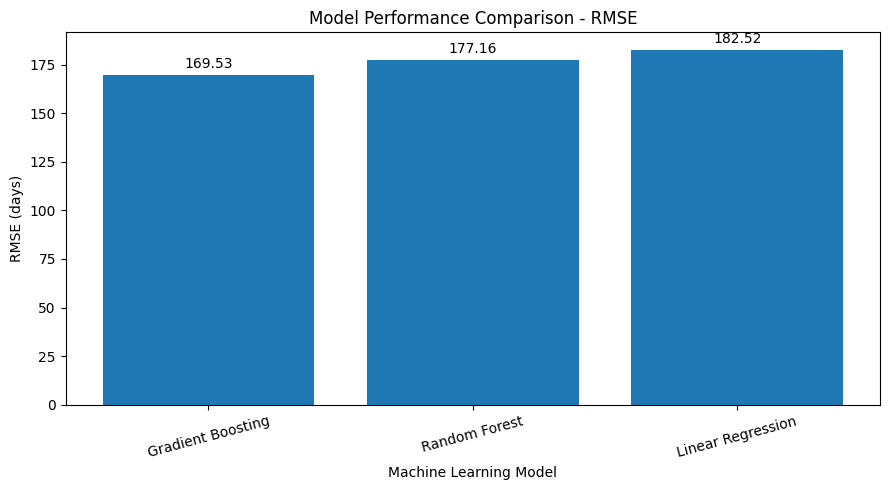

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(results["Model"], results["RMSE (days)"])

plt.title("Model Performance Comparison - RMSE")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (days)")
plt.xticks(rotation=15)

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

In [25]:
print("DATASET OVERVIEW")
print("Total records:", len(df))
print("Unique orders:", df["Order ID"].nunique())
print("Total factories proposed:", 5)
print("Unique products:", df["Product Name"].nunique())

print("\nORDERS BY REGION")
display(
    df.groupby("Region")
      .agg(
          Total_Orders=("Order ID", "count"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum")
      )
      .sort_values("Total_Orders", ascending=False)
      .round(2)
)

print("\nPRODUCT PERFORMANCE")
display(
    product_summary[
        ["Division", "Product Name", "Records",
         "Total_Sales", "Total_Profit", "Total_Units"]
    ].sort_values("Total_Profit", ascending=False).round(2)
)


DATASET OVERVIEW
Total records: 10194
Unique orders: 8549
Total factories proposed: 5
Unique products: 15

ORDERS BY REGION


,Total_Orders,Total_Sales,Total_Profit
Region,,,
Pacific,3253,46301.53,30485.94
Atlantic,2986,41197.24,26973.70
Interior,2335,32037.60,21282.49
Gulf,1620,22247.26,14700.67



PRODUCT PERFORMANCE


,Division,Product Name,Records,Total_Sales,Total_Profit,Total_Units
3,Chocolate,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,19357.50,7743
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,18610.20,7596
1,Chocolate,Wonka Bar - Milk Chocolate,2137,26867.75,17443.37,8267
2,Chocolate,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,16819.95,6755
0,Chocolate,Wonka Bar - Fudge Mallows,1818,24890.40,16593.60,6914
7,Other,Lickable Wallpaper,94,7860.00,3930.00,393
5,Other,Wonka Gum,120,597.50,310.70,478
9,Sugar,Everlasting Gobstopper,3,130.00,104.00,13
6,Other,Kazookles,96,1205.75,92.75,371
11,Sugar,Hair Toffee,4,76.50,59.50,17


In [26]:

!pip -q install gdown

import gdown
import pandas as pd
import numpy as np

file_id = "1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49"
url = f"https://drive.google.com/uc?id={file_id}"
file_path = "/content/Nassau Candy Distributor.csv"

gdown.download(url, file_path, quiet=False)

df = pd.read_csv(file_path)
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%d-%m-%Y", errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%d-%m-%Y", errors="coerce"
)
df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Dataset reloaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))


Downloading...
From: https://drive.google.com/uc?id=1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49
To: /content/Nassau Candy Distributor.csv
100%|██████████| 1.98M/1.98M [00:00<00:00, 48.0MB/s]


Dataset reloaded successfully!
Rows: 10194
Columns: 19


In [27]:

product_summary = (
    df.groupby(["Division", "Product ID", "Product Name"])
      .agg(
          Records=("Order ID", "count"),
          Total_Sales=("Sales", "sum"),
          Total_Cost=("Cost", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum")
      )
      .reset_index()
)

print("Product summary created successfully!")
display(product_summary.head())


Product summary created successfully!


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units
0,Chocolate,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,24890.40,8296.80,16593.60,6914
1,Chocolate,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,26867.75,9424.38,17443.37,8267
2,Chocolate,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,6755.00,16819.95,6755
3,Chocolate,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,8517.30,19357.50,7743
4,Chocolate,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,9874.80,18610.20,7596


In [28]:

print("DATASET OVERVIEW")
print("Total records:", len(df))
print("Unique orders:", df["Order ID"].nunique())
print("Total factories proposed:", 5)
print("Unique products:", df["Product Name"].nunique())

print("\nORDERS BY REGION")
display(
    df.groupby("Region")
      .agg(
          Total_Orders=("Order ID", "count"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum")
      )
      .sort_values("Total_Orders", ascending=False)
      .round(2)
)

print("\nPRODUCT PERFORMANCE")
display(
    product_summary[
        ["Division", "Product Name", "Records",
         "Total_Sales", "Total_Profit", "Total_Units"]
    ].sort_values("Total_Profit", ascending=False).round(2)
)


DATASET OVERVIEW
Total records: 10194
Unique orders: 8549
Total factories proposed: 5
Unique products: 15

ORDERS BY REGION


,Total_Orders,Total_Sales,Total_Profit
Region,,,
Pacific,3253,46301.53,30485.94
Atlantic,2986,41197.24,26973.70
Interior,2335,32037.60,21282.49
Gulf,1620,22247.26,14700.67



PRODUCT PERFORMANCE


,Division,Product Name,Records,Total_Sales,Total_Profit,Total_Units
3,Chocolate,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,19357.50,7743
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,18610.20,7596
1,Chocolate,Wonka Bar - Milk Chocolate,2137,26867.75,17443.37,8267
2,Chocolate,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,16819.95,6755
0,Chocolate,Wonka Bar - Fudge Mallows,1818,24890.40,16593.60,6914
7,Other,Lickable Wallpaper,94,7860.00,3930.00,393
5,Other,Wonka Gum,120,597.50,310.70,478
9,Sugar,Everlasting Gobstopper,3,130.00,104.00,13
6,Other,Kazookles,96,1205.75,92.75,371
11,Sugar,Hair Toffee,4,76.50,59.50,17


In [29]:

factory_assignment = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

product_summary["Proposed Factory"] = (
    product_summary["Product Name"].map(factory_assignment)
)

print("Products without a factory assignment:",
      product_summary["Proposed Factory"].isna().sum())

print("\nPROPOSED FACTORY PERFORMANCE")

factory_summary = (
    product_summary.groupby("Proposed Factory")
    .agg(
        Products=("Product Name", "count"),
        Total_Orders=("Records", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Units=("Total_Units", "sum")
    )
    .sort_values("Total_Profit", ascending=False)
    .round(2)
)

display(factory_summary)


Products without a factory assignment: 0

PROPOSED FACTORY PERFORMANCE


,Products,Total_Orders,Total_Sales,Total_Profit,Total_Units
Proposed Factory,,,,,
Lot's O' Nuts,3,5692,76340.15,52771.05,21412
Wicked Choccy's,2,4152,55352.75,36053.57,15863
Secret Factory,3,217,8587.50,4344.70,884
The Other Factory,2,100,1282.25,152.25,388
Sugar Shack,5,33,220.98,121.23,107


In [30]:

print("SHIPPING LEAD TIME BY REGION")

region_shipping = (
    df.groupby("Region")
      .agg(
          Total_Orders=("Order ID", "count"),
          Average_Lead_Time=("Shipping Lead Time", "mean"),
          Median_Lead_Time=("Shipping Lead Time", "median"),
          Minimum_Lead_Time=("Shipping Lead Time", "min"),
          Maximum_Lead_Time=("Shipping Lead Time", "max")
      )
      .sort_values("Average_Lead_Time")
      .round(2)
)

display(region_shipping)

print("\nSHIPPING LEAD TIME BY SHIPPING MODE")

mode_shipping = (
    df.groupby("Ship Mode")
      .agg(
          Total_Orders=("Order ID", "count"),
          Average_Lead_Time=("Shipping Lead Time", "mean"),
          Median_Lead_Time=("Shipping Lead Time", "median")
      )
      .sort_values("Average_Lead_Time")
      .round(2)
)

display(mode_shipping)


SHIPPING LEAD TIME BY REGION


,Total_Orders,Average_Lead_Time,Median_Lead_Time,Minimum_Lead_Time,Maximum_Lead_Time
Region,,,,,
Gulf,1620,1311.37,1274.0,904,1642
Pacific,3253,1322.19,1274.0,904,1642
Atlantic,2986,1322.75,1274.0,904,1642
Interior,2335,1323.09,1274.0,904,1642



SHIPPING LEAD TIME BY SHIPPING MODE


,Total_Orders,Average_Lead_Time,Median_Lead_Time
Ship Mode,,,
Standard Class,6120,1314.33,1274.0
Second Class,1979,1323.85,1273.0
Same Day,547,1333.44,1269.0
First Class,1548,1338.28,1272.0


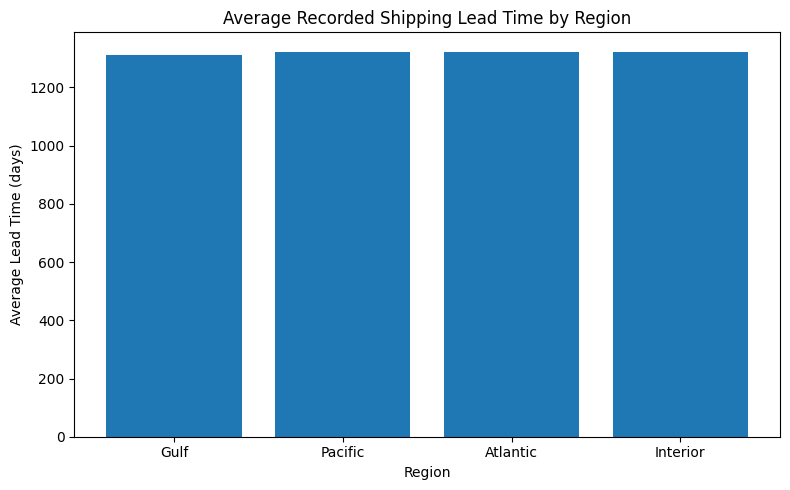

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    region_shipping.index,
    region_shipping["Average_Lead_Time"]
)

plt.title("Average Recorded Shipping Lead Time by Region")
plt.xlabel("Region")
plt.ylabel("Average Lead Time (days)")
plt.tight_layout()
plt.show()


In [32]:

factory_locations = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

print("FACTORY LOCATIONS")
for factory, coordinates in factory_locations.items():
    print(f"{factory}: Latitude {coordinates[0]}, Longitude {coordinates[1]}")


FACTORY LOCATIONS
Lot's O' Nuts: Latitude 32.881893, Longitude -111.768036
Wicked Choccy's: Latitude 32.076176, Longitude -81.088371
Sugar Shack: Latitude 48.11914, Longitude -96.18115
Secret Factory: Latitude 41.446333, Longitude -90.565487
The Other Factory: Latitude 35.1175, Longitude -89.971107


In [33]:

print("LOCATION-RELATED COLUMNS")

location_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ["region", "state", "city", "postal", "zip", "address", "country"])
]

print(location_columns)

print("\nSAMPLE LOCATION DATA")

display(df[location_columns].head(10))

print("\nUNIQUE REGIONS")
print(df["Region"].unique())


LOCATION-RELATED COLUMNS
['Country/Region', 'City', 'State/Province', 'Postal Code', 'Region']

SAMPLE LOCATION DATA


,Country/Region,City,State/Province,Postal Code,Region
0,United States,Houston,Texas,77095,Interior
1,United States,Naperville,Illinois,60540,Interior
2,United States,Naperville,Illinois,60540,Interior
3,United States,Naperville,Illinois,60540,Interior
4,United States,Philadelphia,Pennsylvania,19143,Atlantic
5,United States,Henderson,Kentucky,42420,Gulf
6,United States,Henderson,Kentucky,42420,Gulf
7,United States,Athens,Georgia,30605,Gulf
8,United States,Henderson,Kentucky,42420,Gulf
9,United States,Henderson,Kentucky,42420,Gulf



UNIQUE REGIONS
['Interior' 'Atlantic' 'Gulf' 'Pacific']


In [34]:
destination_summary = (
    df.groupby([
        "Country/Region",
        "State/Province",
        "City",
        "Postal Code",
        "Region"
    ], dropna=False)
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values("Total_Orders", ascending=False)
)

print("Number of unique destination groups:",
      len(destination_summary))

print("\nTOP 15 CUSTOMER DESTINATIONS")

display(destination_summary.head(15).round(2))


Number of unique destination groups: 655

TOP 15 CUSTOMER DESTINATIONS


,Country/Region,State/Province,City,Postal Code,Region,Total_Orders,Total_Sales,Total_Profit
430,United States,New York,New York City,10035,Atlantic,216,3418.30,2272.98
429,United States,New York,New York City,10024,Atlantic,193,2990.88,1962.90
427,United States,New York,New York City,10009,Atlantic,193,3156.51,2068.21
122,United States,California,San Francisco,94122,Pacific,173,2947.09,1936.75
428,United States,New York,New York City,10011,Atlantic,159,2949.21,1936.42
636,United States,Washington,Seattle,98105,Pacific,140,2367.57,1565.01
121,United States,California,San Francisco,94110,Pacific,134,2215.26,1481.84
505,United States,Pennsylvania,Philadelphia,19134,Atlantic,128,2067.48,1352.84
91,United States,California,Los Angeles,90049,Pacific,124,2051.94,1375.38
120,United States,California,San Francisco,94109,Pacific,123,1856.26,1232.18


In [35]:

!pip -q install geopy

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from geopy.distance import geodesic

print("Geographic distance tools installed successfully!")


Geographic distance tools installed successfully!


In [36]:

geolocator = Nominatim(user_agent="factory_shipping_optimization_project")

test_location = geolocator.geocode(
    "10035, New York City, New York, USA",
    timeout=15
)

if test_location:
    print("Location found successfully!")
    print("Address:", test_location.address)
    print("Latitude:", test_location.latitude)
    print("Longitude:", test_location.longitude)
else:
    print("Location not found. We will try another lookup method.")


Location found successfully!
Address: 10035, Manhattan, New York County, New York, United States
Latitude: 40.8006372
Longitude: -73.9369067


In [37]:

!pip -q install pgeocode

import pgeocode
import pandas as pd
import numpy as np

top_destinations = destination_summary.head(15).copy()

postal_lookup = pgeocode.Nominatim("us")

top_destinations["Postal Code"] = (
    top_destinations["Postal Code"]
    .astype(str)
    .str.extract(r"(\d{5})")[0]
)

coordinates = postal_lookup.query_postal_code(
    top_destinations["Postal Code"].tolist()
)

top_destinations["Latitude"] = coordinates["latitude"].to_numpy()
top_destinations["Longitude"] = coordinates["longitude"].to_numpy()

print("Top customer destinations with coordinates:")
display(
    top_destinations[
        ["City", "State/Province", "Postal Code",
         "Total_Orders", "Latitude", "Longitude"]
    ]
)

print("\nDestinations with missing coordinates:",
      top_destinations["Latitude"].isna().sum())


Top customer destinations with coordinates:


,City,State/Province,Postal Code,Total_Orders,Latitude,Longitude
430,New York City,New York,10035,216,40.8011,-73.9371
429,New York City,New York,10024,193,40.7864,-73.9764
427,New York City,New York,10009,193,40.7262,-73.9796
122,San Francisco,California,94122,173,37.7593,-122.4836
428,New York City,New York,10011,159,40.7402,-73.9996
636,Seattle,Washington,98105,140,47.6633,-122.3022
121,San Francisco,California,94110,134,37.7509,-122.4153
505,Philadelphia,Pennsylvania,19134,128,39.9925,-75.1133
91,Los Angeles,California,90049,124,34.0660,-118.4740
120,San Francisco,California,94109,123,37.7917,-122.4186



Destinations with missing coordinates: 0


In [38]:

from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):
    earth_radius = 6371  # kilometres

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * atan2(
        sqrt(a), sqrt(1 - a)
    )

distance_records = []

for _, destination in top_destinations.iterrows():
    for factory, (factory_lat, factory_lon) in factory_locations.items():
        distance_km = calculate_distance(
            factory_lat,
            factory_lon,
            destination["Latitude"],
            destination["Longitude"]
        )

        distance_records.append({
            "City": destination["City"],
            "Postal Code": destination["Postal Code"],
            "Total_Orders": destination["Total_Orders"],
            "Factory": factory,
            "Distance_km": round(distance_km, 2)
        })

distance_df = pd.DataFrame(distance_records)

print("Factory-to-customer distance calculations completed!")
print("Total distance records:", len(distance_df))

display(distance_df.head(15))


Factory-to-customer distance calculations completed!
Total distance records: 75


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,216,Lot's O' Nuts,3450.93
1,New York City,10035,216,Wicked Choccy's,1161.12
2,New York City,10035,216,Sugar Shack,1934.67
3,New York City,10035,216,Secret Factory,1392.53
4,New York City,10035,216,The Other Factory,1538.18
5,New York City,10024,193,Lot's O' Nuts,3447.55
6,New York City,10024,193,Wicked Choccy's,1157.86
7,New York City,10024,193,Sugar Shack,1932.75
8,New York City,10024,193,Secret Factory,1389.50
9,New York City,10024,193,The Other Factory,1534.52


In [39]:


nearest_factory_df = (
    distance_df.loc[
        distance_df.groupby(["City", "Postal Code"])["Distance_km"].idxmin()
    ]
    .sort_values("Total_Orders", ascending=False)
    .reset_index(drop=True)
)

print("Nearest factory for each customer destination:")

display(
    nearest_factory_df[
        ["City", "Postal Code", "Total_Orders",
         "Factory", "Distance_km"]
    ]
)

nearest_factory_summary = (
    nearest_factory_df.groupby("Factory")
    .agg(
        Customer_Destinations=("Postal Code", "count"),
        Associated_Orders=("Total_Orders", "sum"),
        Average_Distance_km=("Distance_km", "mean")
    )
    .reset_index()
    .sort_values("Associated_Orders", ascending=False)
)

print("\nNearest-factory summary:")
display(nearest_factory_summary.round(2))


Nearest factory for each customer destination:


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,216,Wicked Choccy's,1161.12
1,New York City,10009,193,Wicked Choccy's,1152.26
2,New York City,10024,193,Wicked Choccy's,1157.86
3,San Francisco,94122,173,Lot's O' Nuts,1112.18
4,New York City,10011,159,Wicked Choccy's,1152.55
5,Seattle,98105,140,Lot's O' Nuts,1866.88
6,San Francisco,94110,134,Lot's O' Nuts,1106.37
7,Philadelphia,19134,128,Wicked Choccy's,1030.65
8,Los Angeles,90049,124,Lot's O' Nuts,635.64
9,San Francisco,94109,123,Lot's O' Nuts,1108.64



Nearest-factory summary:


,Factory,Customer_Destinations,Associated_Orders,Average_Distance_km
1,Wicked Choccy's,7,1111,1102.79
0,Lot's O' Nuts,8,1036,1118.75


In [40]:

print("Nearest-factory summary:")

display(
    nearest_factory_summary[
        [
            "Factory",
            "Customer_Destinations",
            "Associated_Orders",
            "Average_Distance_km"
        ]
    ].round(2)
)


Nearest-factory summary:


,Factory,Customer_Destinations,Associated_Orders,Average_Distance_km
1,Wicked Choccy's,7,1111,1102.79
0,Lot's O' Nuts,8,1036,1118.75


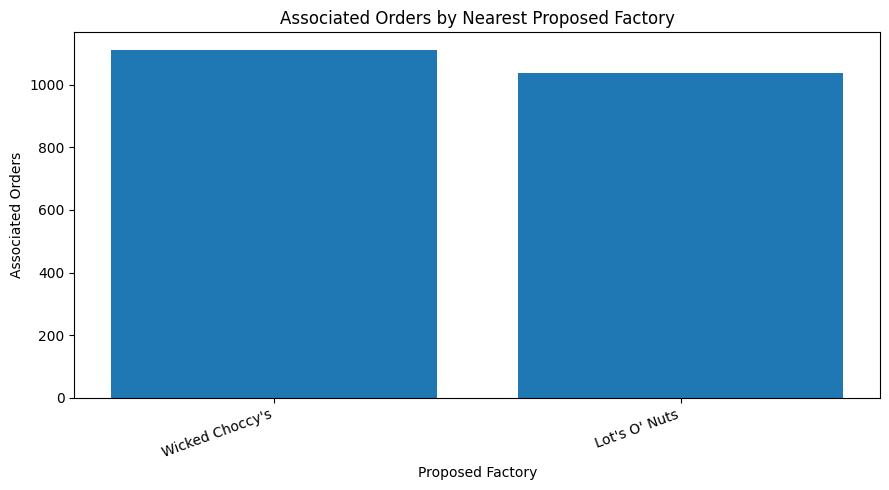

In [41]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    nearest_factory_summary["Factory"],
    nearest_factory_summary["Associated_Orders"]
)

plt.title("Associated Orders by Nearest Proposed Factory")
plt.xlabel("Proposed Factory")
plt.ylabel("Associated Orders")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [42]:

factory_product_summary = (
    product_summary.groupby("Proposed Factory")
    .agg(
        Number_of_Products=("Product Name", "nunique"),
        Total_Orders=("Records", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
    .sort_values("Total_Orders", ascending=False)
)

print("Product allocation by proposed factory:")

display(factory_product_summary.round(2))


Product allocation by proposed factory:


,Proposed Factory,Number_of_Products,Total_Orders,Total_Sales,Total_Profit
0,Lot's O' Nuts,3,5692,76340.15,52771.05
4,Wicked Choccy's,2,4152,55352.75,36053.57
1,Secret Factory,3,217,8587.50,4344.70
3,The Other Factory,2,100,1282.25,152.25
2,Sugar Shack,5,33,220.98,121.23


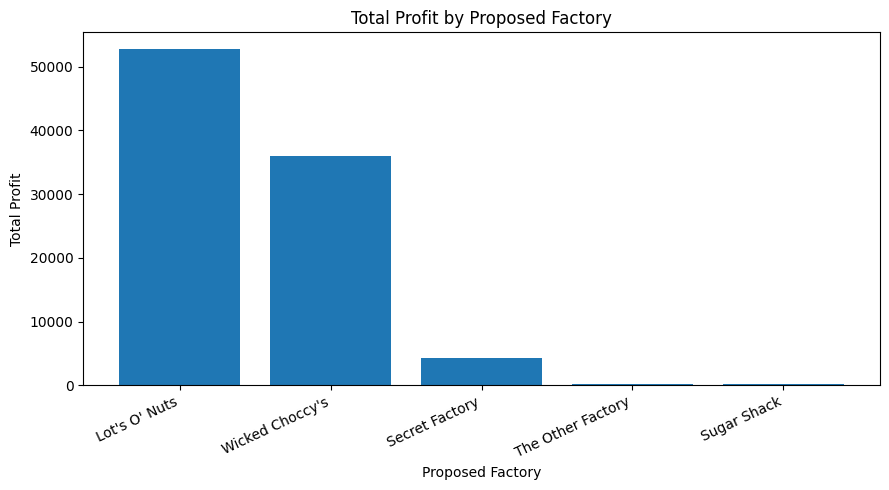

In [43]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    factory_product_summary["Proposed Factory"],
    factory_product_summary["Total_Profit"]
)

plt.title("Total Profit by Proposed Factory")
plt.xlabel("Proposed Factory")
plt.ylabel("Total Profit")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [44]:

factory_product_summary = (
    product_summary.groupby("Proposed Factory")
    .agg(
        Number_of_Products=("Product Name", "nunique"),
        Total_Orders=("Records", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
    .sort_values("Total_Orders", ascending=False)
)

display(factory_product_summary)


,Proposed Factory,Number_of_Products,Total_Orders,Total_Sales,Total_Profit
0,Lot's O' Nuts,3,5692,76340.15,52771.05
4,Wicked Choccy's,2,4152,55352.75,36053.57
1,Secret Factory,3,217,8587.50,4344.70
3,The Other Factory,2,100,1282.25,152.25
2,Sugar Shack,5,33,220.98,121.23


In [45]:
print("df exists:", "df" in globals())
print("product_summary exists:", "product_summary" in globals())

df exists: True
product_summary exists: True


In [46]:

!pip -q install gdown

import gdown
import pandas as pd
import numpy as np

file_id = "1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49"
url = f"https://drive.google.com/uc?id={file_id}"
file_path = "/content/Nassau Candy Distributor.csv"

gdown.download(url, file_path, quiet=False)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Downloading...
From: https://drive.google.com/uc?id=1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49
To: /content/Nassau Candy Distributor.csv
100%|██████████| 1.98M/1.98M [00:00<00:00, 33.2MB/s]


Dataset loaded successfully!
Dataset shape: (10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [47]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

product_summary = (
    df.groupby(["Division", "Product ID", "Product Name"])
    .agg(
        Records=("Order ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Cost=("Cost", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
    .reset_index()
)

factory_assignment = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

product_summary["Proposed Factory"] = (
    product_summary["Product Name"].map(factory_assignment)
)

print("Date columns and product summary restored.")
print("Product summary shape:", product_summary.shape)
print("Products without a factory assignment:",
      product_summary["Proposed Factory"].isna().sum())
print("Rows with missing values:", df.isna().any(axis=1).sum())

display(product_summary.head())


Date columns and product summary restored.
Product summary shape: (15, 9)
Products without a factory assignment: 0
Rows with missing values: 0


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units,Proposed Factory
0,Chocolate,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,24890.40,8296.80,16593.60,6914,Lot's O' Nuts
1,Chocolate,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,26867.75,9424.38,17443.37,8267,Wicked Choccy's
2,Chocolate,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,6755.00,16819.95,6755,Lot's O' Nuts
3,Chocolate,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,8517.30,19357.50,7743,Lot's O' Nuts
4,Chocolate,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,9874.80,18610.20,7596,Wicked Choccy's


In [48]:

factory_product_summary = (
    product_summary.groupby("Proposed Factory")
    .agg(
        Number_of_Products=("Product Name", "nunique"),
        Total_Orders=("Records", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
    .sort_values("Total_Orders", ascending=False)
)

print("Factory performance summary:")
display(factory_product_summary.round(2))


Factory performance summary:


,Proposed Factory,Number_of_Products,Total_Orders,Total_Sales,Total_Profit
0,Lot's O' Nuts,3,5692,76340.15,52771.05
4,Wicked Choccy's,2,4152,55352.75,36053.57
1,Secret Factory,3,217,8587.50,4344.70
3,The Other Factory,2,100,1282.25,152.25
2,Sugar Shack,5,33,220.98,121.23


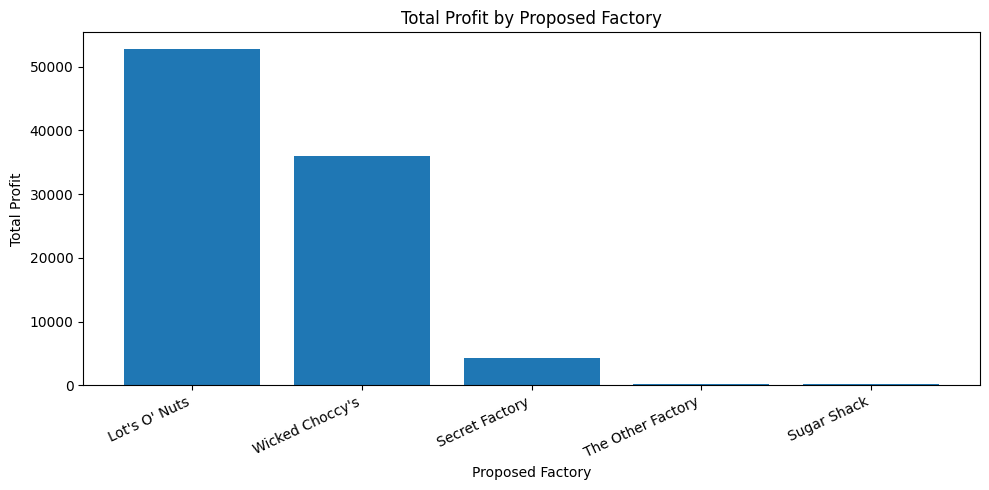

In [49]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    factory_product_summary["Proposed Factory"],
    factory_product_summary["Total_Profit"]
)

plt.title("Total Profit by Proposed Factory")
plt.xlabel("Proposed Factory")
plt.ylabel("Total Profit")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [50]:


for factory, coordinates in factory_locations.items():
    latitude, longitude = coordinates

    print(
        f"{factory}: "
        f"Latitude = {latitude}, "
        f"Longitude = {longitude}"
    )


Lot's O' Nuts: Latitude = 32.881893, Longitude = -111.768036
Wicked Choccy's: Latitude = 32.076176, Longitude = -81.088371
Sugar Shack: Latitude = 48.11914, Longitude = -96.18115
Secret Factory: Latitude = 41.446333, Longitude = -90.565487
The Other Factory: Latitude = 35.1175, Longitude = -89.971107


In [51]:

factory_locations = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

print("Proposed factory locations restored:", len(factory_locations))

for factory, (latitude, longitude) in factory_locations.items():
    print(f"{factory}: Latitude = {latitude}, Longitude = {longitude}")


Proposed factory locations restored: 5
Lot's O' Nuts: Latitude = 32.881893, Longitude = -111.768036
Wicked Choccy's: Latitude = 32.076176, Longitude = -81.088371
Sugar Shack: Latitude = 48.11914, Longitude = -96.18115
Secret Factory: Latitude = 41.446333, Longitude = -90.565487
The Other Factory: Latitude = 35.1175, Longitude = -89.971107


In [52]:

factory_location_df = pd.DataFrame([
    {
        "Factory": factory,
        "Latitude": coordinates[0],
        "Longitude": coordinates[1],
        "Location_Status": "Hypothetical - requires verification"
    }
    for factory, coordinates in factory_locations.items()
])

display(factory_location_df)


,Factory,Latitude,Longitude,Location_Status
0,Lot's O' Nuts,32.881893,-111.768036,Hypothetical - requires verification
1,Wicked Choccy's,32.076176,-81.088371,Hypothetical - requires verification
2,Sugar Shack,48.119140,-96.181150,Hypothetical - requires verification
3,Secret Factory,41.446333,-90.565487,Hypothetical - requires verification
4,The Other Factory,35.117500,-89.971107,Hypothetical - requires verification


In [53]:


allocation_baseline = product_summary[
    [
        "Product Name",
        "Division",
        "Records",
        "Total_Sales",
        "Total_Profit",
        "Proposed Factory"
    ]
].copy()

allocation_baseline = allocation_baseline.sort_values(
    ["Proposed Factory", "Total_Profit"],
    ascending=[True, False]
)

display(allocation_baseline.round(2))

print("Total products:", allocation_baseline["Product Name"].nunique())
print(
    "Products without assignments:",
    allocation_baseline["Proposed Factory"].isna().sum()
)


,Product Name,Division,Records,Total_Sales,Total_Profit,Proposed Factory
3,Wonka Bar -Scrumdiddlyumptious,Chocolate,2064,27874.80,19357.50,Lot's O' Nuts
2,Wonka Bar - Nutty Crunch Surprise,Chocolate,1810,23574.95,16819.95,Lot's O' Nuts
0,Wonka Bar - Fudge Mallows,Chocolate,1818,24890.40,16593.60,Lot's O' Nuts
7,Lickable Wallpaper,Other,94,7860.00,3930.00,Secret Factory
5,Wonka Gum,Other,120,597.50,310.70,Secret Factory
9,Everlasting Gobstopper,Sugar,3,130.00,104.00,Secret Factory
8,Fizzy Lifting Drinks,Sugar,6,78.75,47.25,Sugar Shack
12,Laffy Taffy,Sugar,10,53.73,33.48,Sugar Shack
14,SweeTARTS,Sugar,10,61.50,28.70,Sugar Shack
13,Nerds,Sugar,4,15.00,7.00,Sugar Shack


Total products: 15
Products without assignments: 0


In [54]:


distance_comparison = (
    distance_df.groupby("Factory")
    .apply(
        lambda group: pd.Series({
            "Customer_Destinations": group["Postal Code"].nunique(),
            "Demand_Weighted_Distance_km": (
                (group["Distance_km"] * group["Total_Orders"]).sum()
                / group.drop_duplicates("Postal Code")["Total_Orders"].sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(distance_comparison.round(2))


,Factory,Customer_Destinations,Demand_Weighted_Distance_km
0,Lot's O' Nuts,15.0,2318.65
1,Secret Factory,15.0,1983.85
2,Sugar Shack,15.0,2102.47
3,The Other Factory,15.0,2139.50
4,Wicked Choccy's,15.0,2364.27


In [55]:

from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):
    earth_radius = 6371

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * atan2(
        sqrt(a), sqrt(1 - a)
    )

top_destinations = destination_summary.head(15).copy()

top_destinations["Postal Code"] = (
    top_destinations["Postal Code"]
    .astype(str)
    .str.extract(r"(\d{5})")[0]
)

postal_lookup = pgeocode.Nominatim("us")

coordinates = postal_lookup.query_postal_code(
    top_destinations["Postal Code"].tolist()
)

top_destinations["Latitude"] = coordinates["latitude"].to_numpy()
top_destinations["Longitude"] = coordinates["longitude"].to_numpy()

distance_records = []

for _, destination in top_destinations.iterrows():
    for factory, (factory_lat, factory_lon) in factory_locations.items():
        distance_records.append({
            "City": destination["City"],
            "Postal Code": destination["Postal Code"],
            "Total_Orders": destination["Total_Orders"],
            "Factory": factory,
            "Distance_km": round(
                calculate_distance(
                    factory_lat, factory_lon,
                    destination["Latitude"], destination["Longitude"]
                ),
                2
            )
        })

distance_df = pd.DataFrame(distance_records)

print("Distance table restored!")
print("Distance records:", len(distance_df))
display(distance_df.head())


Distance table restored!
Distance records: 75


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,216,Lot's O' Nuts,3450.93
1,New York City,10035,216,Wicked Choccy's,1161.12
2,New York City,10035,216,Sugar Shack,1934.67
3,New York City,10035,216,Secret Factory,1392.53
4,New York City,10035,216,The Other Factory,1538.18


In [56]:

destination_summary = (
    df.groupby(
        [
            "Country/Region",
            "State/Province",
            "City",
            "Postal Code",
            "Region"
        ],
        dropna=False
    )
    .agg(
        Total_Orders=("Order ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values("Total_Orders", ascending=False)
)

print("Destination summary restored!")
print("Number of destination groups:", len(destination_summary))

display(destination_summary.head(15))


Destination summary restored!
Number of destination groups: 655


,Country/Region,State/Province,City,Postal Code,Region,Total_Orders,Total_Sales,Total_Profit
430,United States,New York,New York City,10035,Atlantic,263,3418.30,2272.98
429,United States,New York,New York City,10024,Atlantic,230,2990.88,1962.90
427,United States,New York,New York City,10009,Atlantic,229,3156.51,2068.21
122,United States,California,San Francisco,94122,Pacific,203,2947.09,1936.75
428,United States,New York,New York City,10011,Atlantic,193,2949.21,1936.42
121,United States,California,San Francisco,94110,Pacific,166,2215.26,1481.84
636,United States,Washington,Seattle,98105,Pacific,165,2367.57,1565.01
505,United States,Pennsylvania,Philadelphia,19134,Atlantic,160,2067.48,1352.84
635,United States,Washington,Seattle,98103,Pacific,151,1978.28,1296.80
91,United States,California,Los Angeles,90049,Pacific,151,2051.94,1375.38


In [57]:

!pip -q install pgeocode

import pgeocode
import pandas as pd
from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):
    earth_radius = 6371
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )
    return 2 * earth_radius * atan2(
        sqrt(a), sqrt(1 - a)
    )

top_destinations = destination_summary.head(15).copy()

top_destinations["Postal Code"] = (
    top_destinations["Postal Code"]
    .astype(str)
    .str.extract(r"(\d{5})")[0]
)

postal_lookup = pgeocode.Nominatim("us")
coordinates = postal_lookup.query_postal_code(
    top_destinations["Postal Code"].tolist()
)

top_destinations["Latitude"] = coordinates["latitude"].to_numpy()
top_destinations["Longitude"] = coordinates["longitude"].to_numpy()

if top_destinations[["Latitude", "Longitude"]].isna().any().any():
    raise ValueError("Some destinations have missing coordinates.")

distance_records = []

for _, destination in top_destinations.iterrows():
    for factory, (factory_lat, factory_lon) in factory_locations.items():
        distance_records.append({
            "City": destination["City"],
            "Postal Code": destination["Postal Code"],
            "Total_Orders": destination["Total_Orders"],
            "Factory": factory,
            "Distance_km": round(
                calculate_distance(
                    factory_lat, factory_lon,
                    destination["Latitude"], destination["Longitude"]
                ),
                2
            )
        })

distance_df = pd.DataFrame(distance_records)

print("Distance calculations completed!")
print("Total distance records:", len(distance_df))
display(distance_df.head(10))


Distance calculations completed!
Total distance records: 75


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,263,Lot's O' Nuts,3450.93
1,New York City,10035,263,Wicked Choccy's,1161.12
2,New York City,10035,263,Sugar Shack,1934.67
3,New York City,10035,263,Secret Factory,1392.53
4,New York City,10035,263,The Other Factory,1538.18
5,New York City,10024,230,Lot's O' Nuts,3447.55
6,New York City,10024,230,Wicked Choccy's,1157.86
7,New York City,10024,230,Sugar Shack,1932.75
8,New York City,10024,230,Secret Factory,1389.50
9,New York City,10024,230,The Other Factory,1534.52


In [58]:

nearest_factory_df = (
    distance_df.loc[
        distance_df.groupby(
            ["City", "Postal Code"]
        )["Distance_km"].idxmin()
    ]
    .sort_values("Total_Orders", ascending=False)
    .reset_index(drop=True)
)

print("Nearest factory for each customer destination:")
display(
    nearest_factory_df[
        ["City", "Postal Code", "Total_Orders",
         "Factory", "Distance_km"]
    ]
)

nearest_factory_summary = (
    nearest_factory_df.groupby("Factory")
    .agg(
        Customer_Destinations=("Postal Code", "count"),
        Associated_Orders=("Total_Orders", "sum"),
        Average_Distance_km=("Distance_km", "mean")
    )
    .reset_index()
    .sort_values("Associated_Orders", ascending=False)
)

print("\nNearest-factory summary:")
display(nearest_factory_summary.round(2))


Nearest factory for each customer destination:


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,263,Wicked Choccy's,1161.12
1,New York City,10024,230,Wicked Choccy's,1157.86
2,New York City,10009,229,Wicked Choccy's,1152.26
3,San Francisco,94122,203,Lot's O' Nuts,1112.18
4,New York City,10011,193,Wicked Choccy's,1152.55
5,San Francisco,94110,166,Lot's O' Nuts,1106.37
6,Seattle,98105,165,Lot's O' Nuts,1866.88
7,Philadelphia,19134,160,Wicked Choccy's,1030.65
8,Seattle,98103,151,Lot's O' Nuts,1869.43
9,Los Angeles,90049,151,Lot's O' Nuts,635.64



Nearest-factory summary:


,Factory,Customer_Destinations,Associated_Orders,Average_Distance_km
0,Lot's O' Nuts,8,1239,1118.75
2,Wicked Choccy's,6,1225,1114.23
1,Secret Factory,1,120,656.92


In [59]:

distance_comparison = (
    distance_df.groupby("Factory")
    .apply(
        lambda group: pd.Series({
            "Customer_Destinations": group["Postal Code"].nunique(),
            "Demand_Weighted_Distance_km": (
                (group["Distance_km"] * group["Total_Orders"]).sum()
                / group.drop_duplicates("Postal Code")["Total_Orders"].sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(distance_comparison.round(2))


,Factory,Customer_Destinations,Demand_Weighted_Distance_km
0,Lot's O' Nuts,15.0,2294.94
1,Secret Factory,15.0,1949.21
2,Sugar Shack,15.0,2076.65
3,The Other Factory,15.0,2107.73
4,Wicked Choccy's,15.0,2350.04


In [60]:

nearest_total_orders = nearest_factory_df["Total_Orders"].sum()

nearest_weighted_distance = (
    (
        nearest_factory_df["Distance_km"]
        * nearest_factory_df["Total_Orders"]
    ).sum()
    / nearest_total_orders
)

print("Number of destinations:", len(nearest_factory_df))
print("Total orders represented:", nearest_total_orders)
print(
    "Demand-weighted nearest-factory distance:",
    round(nearest_weighted_distance, 2),
    "km"
)

print("\nOrders assigned to each nearest factory:")
display(
    nearest_factory_summary[
        ["Factory", "Customer_Destinations", "Associated_Orders"]
    ]
)


Number of destinations: 15
Total orders represented: 2584
Demand-weighted nearest-factory distance: 1111.57 km

Orders assigned to each nearest factory:


,Factory,Customer_Destinations,Associated_Orders
0,Lot's O' Nuts,8,1239
2,Wicked Choccy's,6,1225
1,Secret Factory,1,120


In [61]:
print("DEMAND-WEIGHTED DISTANCE BY FACTORY")
display(
    distance_comparison.sort_values(
        "Demand_Weighted_Distance_km"
    ).round(2)
)

DEMAND-WEIGHTED DISTANCE BY FACTORY


,Factory,Customer_Destinations,Demand_Weighted_Distance_km
1,Secret Factory,15.0,1949.21
2,Sugar Shack,15.0,2076.65
3,The Other Factory,15.0,2107.73
0,Lot's O' Nuts,15.0,2294.94
4,Wicked Choccy's,15.0,2350.04


In [62]:

best_factory_row = distance_comparison.loc[
    distance_comparison["Demand_Weighted_Distance_km"].idxmin()
]

worst_factory_row = distance_comparison.loc[
    distance_comparison["Demand_Weighted_Distance_km"].idxmax()
]

distance_difference = (
    worst_factory_row["Demand_Weighted_Distance_km"]
    - best_factory_row["Demand_Weighted_Distance_km"]
)

percentage_difference = (
    distance_difference
    / worst_factory_row["Demand_Weighted_Distance_km"]
) * 100

print("Lowest-distance factory:", best_factory_row["Factory"])
print(
    "Lowest demand-weighted distance:",
    round(best_factory_row["Demand_Weighted_Distance_km"], 2),
    "km"
)

print("\nHighest-distance factory:", worst_factory_row["Factory"])
print(
    "Highest demand-weighted distance:",
    round(worst_factory_row["Demand_Weighted_Distance_km"], 2),
    "km"
)

print(
    "\nDistance difference:",
    round(distance_difference, 2),
    "km"
)

print(
    "Percentage lower than the highest-distance option:",
    round(percentage_difference, 2),
    "%"
)

Lowest-distance factory: Secret Factory
Lowest demand-weighted distance: 1949.21 km

Highest-distance factory: Wicked Choccy's
Highest demand-weighted distance: 2350.04 km

Distance difference: 400.82 km
Percentage lower than the highest-distance option: 17.06 %


In [63]:

nearest_total_weighted_distance = (
    nearest_factory_df["Distance_km"]
    * nearest_factory_df["Total_Orders"]
).sum()

print(
    "Total demand-weighted distance:",
    round(nearest_total_weighted_distance, 2),
    "order-km"
)

print(
    "Number of destinations:",
    nearest_factory_df["Postal Code"].nunique()
)

print(
    "Total orders:",
    nearest_factory_df["Total_Orders"].sum()
)

Total demand-weighted distance: 2872298.84 order-km
Number of destinations: 15
Total orders: 2584


In [64]:

factory_assignment_df = pd.DataFrame(
    list(factory_assignment.items()),
    columns=["Product Name", "Assigned Factory"]
)

print("Total products assigned:", len(factory_assignment_df))
print(
    "Number of factories used:",
    factory_assignment_df["Assigned Factory"].nunique()
)

print("\nProducts assigned to each factory:")
display(
    factory_assignment_df.groupby("Assigned Factory")
    .agg(
        Number_of_Products=("Product Name", "count"),
        Products=("Product Name", lambda x: ", ".join(x))
    )
    .reset_index()
)

Total products assigned: 15
Number of factories used: 5

Products assigned to each factory:


,Assigned Factory,Number_of_Products,Products
0,Lot's O' Nuts,3,"Wonka Bar - Nutty Crunch Surprise, Wonka Bar -..."
1,Secret Factory,3,"Everlasting Gobstopper, Lickable Wallpaper, Wo..."
2,Sugar Shack,5,"Laffy Taffy, SweeTARTS, Nerds, Fun Dip, Fizzy ..."
3,The Other Factory,2,"Hair Toffee, Kazookles"
4,Wicked Choccy's,2,"Wonka Bar - Milk Chocolate, Wonka Bar - Triple..."


In [65]:


product_factory_analysis = product_summary.merge(
    factory_assignment_df,
    on="Product Name",
    how="left"
)

print("Products without a factory assignment:",
      product_factory_analysis["Assigned Factory"].isna().sum())

print("\nProduct-level sales and profit by assigned factory:")
display(
    product_factory_analysis[
        [
            "Product Name",
            "Assigned Factory",
            "Total_Sales",
            "Total_Profit",
            "Total_Units"
        ]
    ].sort_values("Total_Profit", ascending=False).round(2)
)


Products without a factory assignment: 0

Product-level sales and profit by assigned factory:


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Total_Units
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,27874.80,19357.50,7743
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,28485.00,18610.20,7596
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,26867.75,17443.37,8267
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,23574.95,16819.95,6755
0,Wonka Bar - Fudge Mallows,Lot's O' Nuts,24890.40,16593.60,6914
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,393
5,Wonka Gum,Secret Factory,597.50,310.70,478
9,Everlasting Gobstopper,Secret Factory,130.00,104.00,13
6,Kazookles,The Other Factory,1205.75,92.75,371
11,Hair Toffee,The Other Factory,76.50,59.50,17


In [66]:

factory_performance = (
    product_factory_analysis
    .groupby("Assigned Factory")
    .agg(
        Number_of_Products=("Product Name", "count"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Units=("Total_Units", "sum")
    )
    .reset_index()
    .sort_values("Total_Profit", ascending=False)
)

factory_performance[
    ["Total_Sales", "Total_Profit"]
] = factory_performance[
    ["Total_Sales", "Total_Profit"]
].round(2)

print("FACTORY PERFORMANCE SUMMARY")
display(factory_performance)


FACTORY PERFORMANCE SUMMARY


,Assigned Factory,Number_of_Products,Total_Sales,Total_Profit,Total_Units
0,Lot's O' Nuts,3,76340.15,52771.05,21412
4,Wicked Choccy's,2,55352.75,36053.57,15863
1,Secret Factory,3,8587.50,4344.70,884
3,The Other Factory,2,1282.25,152.25,388
2,Sugar Shack,5,220.98,121.23,107


In [67]:

factory_performance["Profit_Margin_Percent"] = (
    factory_performance["Total_Profit"]
    / factory_performance["Total_Sales"]
) * 100

factory_performance["Profit_Margin_Percent"] = (
    factory_performance["Profit_Margin_Percent"].round(2)
)

print("FACTORY PROFITABILITY ANALYSIS")

display(
    factory_performance[
        [
            "Assigned Factory",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_Percent"
        ]
    ].sort_values("Profit_Margin_Percent", ascending=False)
)


FACTORY PROFITABILITY ANALYSIS


,Assigned Factory,Total_Sales,Total_Profit,Profit_Margin_Percent
0,Lot's O' Nuts,76340.15,52771.05,69.13
4,Wicked Choccy's,55352.75,36053.57,65.13
2,Sugar Shack,220.98,121.23,54.86
1,Secret Factory,8587.50,4344.70,50.59
3,The Other Factory,1282.25,152.25,11.87


In [68]:

product_factory_analysis["Profit_Margin_Percent"] = (
    product_factory_analysis["Total_Profit"]
    / product_factory_analysis["Total_Sales"].replace(0, float("nan"))
) * 100

product_factory_analysis["Profit_Margin_Percent"] = (
    product_factory_analysis["Profit_Margin_Percent"].round(2)
)

product_factory_analysis["Review_Recommendation"] = (
    product_factory_analysis["Profit_Margin_Percent"]
    .apply(
        lambda margin: (
            "Review profitability"
            if margin < 20
            else "No low-margin flag"
        )
    )
)

print("PRODUCTS FLAGGED FOR PROFITABILITY REVIEW")

display(
    product_factory_analysis[
        [
            "Product Name",
            "Assigned Factory",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_Percent",
            "Review_Recommendation"
        ]
    ].sort_values("Profit_Margin_Percent", ascending=True)
)


PRODUCTS FLAGGED FOR PROFITABILITY REVIEW


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Profit_Margin_Percent,Review_Recommendation
6,Kazookles,The Other Factory,1205.75,92.75,7.69,Review profitability
10,Fun Dip,Sugar Shack,12.00,4.80,40.00,No low-margin flag
13,Nerds,Sugar Shack,15.00,7.00,46.67,No low-margin flag
14,SweeTARTS,Sugar Shack,61.50,28.70,46.67,No low-margin flag
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,50.00,No low-margin flag
5,Wonka Gum,Secret Factory,597.50,310.70,52.00,No low-margin flag
8,Fizzy Lifting Drinks,Sugar Shack,78.75,47.25,60.00,No low-margin flag
12,Laffy Taffy,Sugar Shack,53.73,33.48,62.31,No low-margin flag
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,26867.75,17443.37,64.92,No low-margin flag
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,28485.00,18610.20,65.33,No low-margin flag


In [69]:


display(
    product_summary.loc[
        product_summary["Product Name"] == "Hair Toffee"
    ]
)

print("\nSales and profit data types:")
print(product_summary[["Total_Sales", "Total_Profit"]].dtypes)

print("\nCurrent calculated margin:")
display(
    product_factory_analysis.loc[
        product_factory_analysis["Product Name"] == "Hair Toffee",
        ["Product Name", "Total_Sales", "Total_Profit",
         "Profit_Margin_Percent"]
    ]
)


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units,Proposed Factory
11,Sugar,SUG-HAI-55000,Hair Toffee,4,76.5,17.0,59.5,17,The Other Factory



Sales and profit data types:
Total_Sales     float64
Total_Profit    float64
dtype: object

Current calculated margin:


,Product Name,Total_Sales,Total_Profit,Profit_Margin_Percent
11,Hair Toffee,76.5,59.5,77.78


In [70]:

product_factory_analysis["Review_Recommendation"] = (
    product_factory_analysis["Profit_Margin_Percent"]
    .apply(
        lambda margin: (
            "Review profitability"
            if pd.notna(margin) and margin < 20
            else "No low-margin flag"
        )
    )
)

print("UPDATED PROFITABILITY RECOMMENDATIONS")

display(
    product_factory_analysis[
        [
            "Product Name",
            "Assigned Factory",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_Percent",
            "Review_Recommendation"
        ]
    ].sort_values("Profit_Margin_Percent", ascending=True)
)


UPDATED PROFITABILITY RECOMMENDATIONS


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Profit_Margin_Percent,Review_Recommendation
6,Kazookles,The Other Factory,1205.75,92.75,7.69,Review profitability
10,Fun Dip,Sugar Shack,12.00,4.80,40.00,No low-margin flag
13,Nerds,Sugar Shack,15.00,7.00,46.67,No low-margin flag
14,SweeTARTS,Sugar Shack,61.50,28.70,46.67,No low-margin flag
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,50.00,No low-margin flag
5,Wonka Gum,Secret Factory,597.50,310.70,52.00,No low-margin flag
8,Fizzy Lifting Drinks,Sugar Shack,78.75,47.25,60.00,No low-margin flag
12,Laffy Taffy,Sugar Shack,53.73,33.48,62.31,No low-margin flag
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,26867.75,17443.37,64.92,No low-margin flag
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,28485.00,18610.20,65.33,No low-margin flag


In [71]:

recommendation_df = product_factory_analysis[
    [
        "Product Name",
        "Assigned Factory",
        "Total_Sales",
        "Total_Profit",
        "Total_Units",
        "Profit_Margin_Percent",
        "Review_Recommendation"
    ]
].copy()

recommendation_df["Next_Action"] = (
    recommendation_df["Review_Recommendation"]
    .map({
        "Review profitability":
            "Investigate product costs and factory suitability",
        "No low-margin flag":
            "Retain provisionally; evaluate shipping and capacity"
    })
)

print("CONSOLIDATED FACTORY RECOMMENDATIONS")

display(
    recommendation_df.sort_values(
        ["Review_Recommendation", "Total_Profit"],
        ascending=[True, True]
    ).round(2)
)

print("\nProducts included:", len(recommendation_df))
print(
    "Products flagged for profitability review:",
    (recommendation_df["Review_Recommendation"]
     == "Review profitability").sum()
)


CONSOLIDATED FACTORY RECOMMENDATIONS


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Total_Units,Profit_Margin_Percent,Review_Recommendation,Next_Action
10,Fun Dip,Sugar Shack,12.00,4.80,8,40.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
13,Nerds,Sugar Shack,15.00,7.00,10,46.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...
14,SweeTARTS,Sugar Shack,61.50,28.70,41,46.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...
12,Laffy Taffy,Sugar Shack,53.73,33.48,27,62.31,No low-margin flag,Retain provisionally; evaluate shipping and ca...
8,Fizzy Lifting Drinks,Sugar Shack,78.75,47.25,21,60.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
11,Hair Toffee,The Other Factory,76.50,59.50,17,77.78,No low-margin flag,Retain provisionally; evaluate shipping and ca...
9,Everlasting Gobstopper,Secret Factory,130.00,104.00,13,80.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
5,Wonka Gum,Secret Factory,597.50,310.70,478,52.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,393,50.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
0,Wonka Bar - Fudge Mallows,Lot's O' Nuts,24890.40,16593.60,6914,66.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...



Products included: 15
Products flagged for profitability review: 1


In [72]:

recommendation_df = product_factory_analysis[
    [
        "Product Name",
        "Assigned Factory",
        "Total_Sales",
        "Total_Profit",
        "Total_Units",
        "Profit_Margin_Percent",
    ]
].copy()

recommendation_df["Review_Recommendation"] = (
    recommendation_df["Profit_Margin_Percent"].apply(
        lambda margin: (
            "Review profitability"
            if pd.notna(margin) and margin < 20
            else "No low-margin flag"
        )
    )
)

recommendation_df["Next_Action"] = recommendation_df[
    "Review_Recommendation"
].map({
    "Review profitability":
        "Investigate product costs and factory suitability",
    "No low-margin flag":
        "Retain provisionally; evaluate shipping and capacity"
})

print("Total products:", len(recommendation_df))
print(
    "Missing profit margins:",
    recommendation_df["Profit_Margin_Percent"].isna().sum()
)
print(
    "Missing recommendations:",
    recommendation_df["Next_Action"].isna().sum()
)

display(
    recommendation_df.sort_values(
        "Profit_Margin_Percent",
        ascending=True,
        na_position="last"
    ).round(2)
)


Total products: 15
Missing profit margins: 0
Missing recommendations: 0


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Total_Units,Profit_Margin_Percent,Review_Recommendation,Next_Action
6,Kazookles,The Other Factory,1205.75,92.75,371,7.69,Review profitability,Investigate product costs and factory suitability
10,Fun Dip,Sugar Shack,12.00,4.80,8,40.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
13,Nerds,Sugar Shack,15.00,7.00,10,46.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...
14,SweeTARTS,Sugar Shack,61.50,28.70,41,46.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,393,50.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
5,Wonka Gum,Secret Factory,597.50,310.70,478,52.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
8,Fizzy Lifting Drinks,Sugar Shack,78.75,47.25,21,60.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
12,Laffy Taffy,Sugar Shack,53.73,33.48,27,62.31,No low-margin flag,Retain provisionally; evaluate shipping and ca...
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,26867.75,17443.37,8267,64.92,No low-margin flag,Retain provisionally; evaluate shipping and ca...
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,28485.00,18610.20,7596,65.33,No low-margin flag,Retain provisionally; evaluate shipping and ca...


In [73]:

display(
    recommendation_df.tail(7)[
        [
            "Product Name",
            "Assigned Factory",
            "Profit_Margin_Percent",
            "Review_Recommendation",
            "Next_Action"
        ]
    ].to_string(index=False)
)


'          Product Name  Assigned Factory  Profit_Margin_Percent Review_Recommendation                                          Next_Action\n  Fizzy Lifting Drinks       Sugar Shack                  60.00    No low-margin flag Retain provisionally; evaluate shipping and capacity\nEverlasting Gobstopper    Secret Factory                  80.00    No low-margin flag Retain provisionally; evaluate shipping and capacity\n               Fun Dip       Sugar Shack                  40.00    No low-margin flag Retain provisionally; evaluate shipping and capacity\n           Hair Toffee The Other Factory                  77.78    No low-margin flag Retain provisionally; evaluate shipping and capacity\n           Laffy Taffy       Sugar Shack                  62.31    No low-margin flag Retain provisionally; evaluate shipping and capacity\n                 Nerds       Sugar Shack                  46.67    No low-margin flag Retain provisionally; evaluate shipping and capacity\n             SweeTA

In [74]:
print("Total products:", len(recommendation_df))
print("Total sales:", round(recommendation_df["Total_Sales"].sum(), 2))
print("Total profit:", round(recommendation_df["Total_Profit"].sum(), 2))
print("Products flagged:", (recommendation_df["Review_Recommendation"] == "Review profitability").sum())

Total products: 15
Total sales: 141783.63
Total profit: 93442.8
Products flagged: 1


In [75]:

output_file = "factory_recommendations.csv"

recommendation_df.to_csv(output_file, index=False)

print("Recommendation file saved successfully:", output_file)
print("Rows exported:", len(recommendation_df))


Recommendation file saved successfully: factory_recommendations.csv
Rows exported: 15


In [76]:
from google.colab import files
files.download("factory_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:

factory_performance.to_csv(
    "factory_performance_summary.csv", index=False
)

nearest_factory_df.to_csv(
    "nearest_factory_assignments.csv", index=False
)

distance_comparison.to_csv(
    "factory_distance_comparison.csv", index=False
)

print("All three analysis files saved successfully!")

All three analysis files saved successfully!


In [78]:

variables_to_check = [
    "df",
    "product_summary",
    "factory_assignment_df",
    "factory_performance",
    "nearest_factory_df",
    "distance_comparison",
    "recommendation_df"
]

for variable in variables_to_check:
    print(variable, ":", variable in globals())

df : True
product_summary : True
factory_assignment_df : True
factory_performance : True
nearest_factory_df : True
distance_comparison : True
recommendation_df : True


In [79]:
import pandas as pd

file_id = "1c4VDb0Pf7RCgps4aLMiSuLtdaUpU_X49"
url = f"https://drive.google.com/uc?id={file_id}"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Rows and columns: (10194, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [80]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Dataset shape:", df.shape)
print("\nMissing values in date columns:")
print(df[["Order Date", "Ship Date", "Shipping Lead Time"]].isnull().sum())

print("\nShipping lead time summary:")
print(df["Shipping Lead Time"].describe())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (10194, 19)

Missing values in date columns:
Order Date            0
Ship Date             0
Shipping Lead Time    0
dtype: int64

Shipping lead time summary:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64

First five rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912


In [81]:

product_summary = (
    df.groupby(
        ["Division", "Product ID", "Product Name"],
        as_index=False
    )
    .agg(
        Records=("Row ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Cost=("Cost", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
)

print("Number of unique products:", len(product_summary))
print("\nProduct summary:")
display(product_summary)

Number of unique products: 15

Product summary:


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units
0,Chocolate,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,24890.40,8296.80,16593.60,6914
1,Chocolate,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,26867.75,9424.38,17443.37,8267
2,Chocolate,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,6755.00,16819.95,6755
3,Chocolate,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,8517.30,19357.50,7743
4,Chocolate,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,9874.80,18610.20,7596
5,Other,OTH-GUM-21000,Wonka Gum,120,597.50,286.80,310.70,478
6,Other,OTH-KAZ-38000,Kazookles,96,1205.75,1113.00,92.75,371
7,Other,OTH-LIC-15000,Lickable Wallpaper,94,7860.00,3930.00,3930.00,393
8,Sugar,OTH-FIZ-56000,Fizzy Lifting Drinks,6,78.75,31.50,47.25,21
9,Sugar,SUG-EVE-47000,Everlasting Gobstopper,3,130.00,26.00,104.00,13


In [82]:

factory_assignment = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

factory_assignment_df = pd.DataFrame(
    list(factory_assignment.items()),
    columns=["Product Name", "Assigned Factory"]
)

product_factory_check = product_summary.merge(
    factory_assignment_df,
    on="Product Name",
    how="left"
)

print("Total products:", len(product_factory_check))
print(
    "Products without a factory assignment:",
    product_factory_check["Assigned Factory"].isna().sum()
)

display(product_factory_check)

Total products: 15
Products without a factory assignment: 0


,Division,Product ID,Product Name,Records,Total_Sales,Total_Cost,Total_Profit,Total_Units,Assigned Factory
0,Chocolate,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,24890.40,8296.80,16593.60,6914,Lot's O' Nuts
1,Chocolate,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,26867.75,9424.38,17443.37,8267,Wicked Choccy's
2,Chocolate,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,23574.95,6755.00,16819.95,6755,Lot's O' Nuts
3,Chocolate,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,27874.80,8517.30,19357.50,7743,Lot's O' Nuts
4,Chocolate,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,28485.00,9874.80,18610.20,7596,Wicked Choccy's
5,Other,OTH-GUM-21000,Wonka Gum,120,597.50,286.80,310.70,478,Secret Factory
6,Other,OTH-KAZ-38000,Kazookles,96,1205.75,1113.00,92.75,371,The Other Factory
7,Other,OTH-LIC-15000,Lickable Wallpaper,94,7860.00,3930.00,3930.00,393,Secret Factory
8,Sugar,OTH-FIZ-56000,Fizzy Lifting Drinks,6,78.75,31.50,47.25,21,Sugar Shack
9,Sugar,SUG-EVE-47000,Everlasting Gobstopper,3,130.00,26.00,104.00,13,Secret Factory


In [83]:

factory_performance = (
    product_factory_check.groupby("Assigned Factory", as_index=False)
    .agg(
        Products=("Product Name", "nunique"),
        Records=("Records", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Units=("Total_Units", "sum")
    )
)

factory_performance["Profit_Margin_Percent"] = (
    factory_performance["Total_Profit"]
    / factory_performance["Total_Sales"]
    * 100
).round(2)

print("Factory performance summary:")
display(
    factory_performance.sort_values(
        "Total_Profit", ascending=False
    )
)

Factory performance summary:


,Assigned Factory,Products,Records,Total_Sales,Total_Profit,Total_Units,Profit_Margin_Percent
0,Lot's O' Nuts,3,5692,76340.15,52771.05,21412,69.13
4,Wicked Choccy's,2,4152,55352.75,36053.57,15863,65.13
1,Secret Factory,3,217,8587.50,4344.70,884,50.59
3,The Other Factory,2,100,1282.25,152.25,388,11.87
2,Sugar Shack,5,33,220.98,121.23,107,54.86


In [84]:

product_factory_analysis = product_factory_check.copy()

product_factory_analysis["Profit_Margin_Percent"] = (
    product_factory_analysis["Total_Profit"]
    / product_factory_analysis["Total_Sales"]
    * 100
).round(2)

product_factory_analysis["Review_Recommendation"] = (
    product_factory_analysis["Profit_Margin_Percent"]
    .apply(
        lambda margin: "Review profitability"
        if margin < 20
        else "No low-margin flag"
    )
)

product_factory_analysis["Next_Action"] = (
    product_factory_analysis["Review_Recommendation"]
    .map({
        "Review profitability":
            "Investigate product costs and factory suitability",
        "No low-margin flag":
            "Retain provisionally; evaluate shipping and capacity"
    })
)

recommendation_df = product_factory_analysis[
    [
        "Product Name",
        "Assigned Factory",
        "Total_Sales",
        "Total_Profit",
        "Total_Units",
        "Profit_Margin_Percent",
        "Review_Recommendation",
        "Next_Action"
    ]
].copy()

print("Total products:", len(recommendation_df))
print(
    "Products flagged for review:",
    (recommendation_df["Review_Recommendation"]
     == "Review profitability").sum()
)

display(recommendation_df)

Total products: 15
Products flagged for review: 1


,Product Name,Assigned Factory,Total_Sales,Total_Profit,Total_Units,Profit_Margin_Percent,Review_Recommendation,Next_Action
0,Wonka Bar - Fudge Mallows,Lot's O' Nuts,24890.40,16593.60,6914,66.67,No low-margin flag,Retain provisionally; evaluate shipping and ca...
1,Wonka Bar - Milk Chocolate,Wicked Choccy's,26867.75,17443.37,8267,64.92,No low-margin flag,Retain provisionally; evaluate shipping and ca...
2,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,23574.95,16819.95,6755,71.35,No low-margin flag,Retain provisionally; evaluate shipping and ca...
3,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,27874.80,19357.50,7743,69.44,No low-margin flag,Retain provisionally; evaluate shipping and ca...
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,28485.00,18610.20,7596,65.33,No low-margin flag,Retain provisionally; evaluate shipping and ca...
5,Wonka Gum,Secret Factory,597.50,310.70,478,52.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
6,Kazookles,The Other Factory,1205.75,92.75,371,7.69,Review profitability,Investigate product costs and factory suitability
7,Lickable Wallpaper,Secret Factory,7860.00,3930.00,393,50.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
8,Fizzy Lifting Drinks,Sugar Shack,78.75,47.25,21,60.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...
9,Everlasting Gobstopper,Secret Factory,130.00,104.00,13,80.00,No low-margin flag,Retain provisionally; evaluate shipping and ca...


In [85]:

recommendation_df.to_csv(
    "factory_recommendations.csv", index=False
)

factory_performance.to_csv(
    "factory_performance_summary.csv", index=False
)

product_summary.to_csv(
    "product_summary.csv", index=False
)

print("Files saved successfully!")
print("\n1. factory_recommendations.csv")
print("2. factory_performance_summary.csv")
print("3. product_summary.csv")

Files saved successfully!

1. factory_recommendations.csv
2. factory_performance_summary.csv
3. product_summary.csv


In [86]:
from google.colab import files

files.download("factory_recommendations.csv")
files.download("factory_performance_summary.csv")
files.download("product_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE (days)": [
        181.44,
        148.36,
        159.58
    ],
    "RMSE (days)": [
        182.52,
        177.16,
        169.53
    ],
    "R2 Score": [
        0.5290,
        0.5562,
        0.5936
    ]
})

model_comparison.to_csv(
    "model_comparison.csv", index=False
)

print("Model comparison saved successfully!")
display(model_comparison)

Model comparison saved successfully!


,Model,MAE (days),RMSE (days),R2 Score
0,Linear Regression,181.44,182.52,0.5290
1,Random Forest,148.36,177.16,0.5562
2,Gradient Boosting,159.58,169.53,0.5936


In [88]:
from google.colab import files

files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [89]:
print("Nearest-factory data available:",
      "nearest_factory_df" in globals())

print("Distance comparison available:",
      "distance_comparison" in globals())

Nearest-factory data available: True
Distance comparison available: True


In [90]:

factory_locations = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

factory_location_df = pd.DataFrame([
    {
        "Factory": name,
        "Latitude": coords[0],
        "Longitude": coords[1],
        "Location_Status": "Hypothetical - requires verification"
    }
    for name, coords in factory_locations.items()
])

print("Number of proposed factory locations:",
      len(factory_location_df))

display(factory_location_df)

Number of proposed factory locations: 5


,Factory,Latitude,Longitude,Location_Status
0,Lot's O' Nuts,32.881893,-111.768036,Hypothetical - requires verification
1,Wicked Choccy's,32.076176,-81.088371,Hypothetical - requires verification
2,Sugar Shack,48.119140,-96.181150,Hypothetical - requires verification
3,Secret Factory,41.446333,-90.565487,Hypothetical - requires verification
4,The Other Factory,35.117500,-89.971107,Hypothetical - requires verification


In [91]:

print("Destination summary available:", "destination_summary" in globals())

if "destination_summary" in globals():
    print("Destination summary shape:", destination_summary.shape)
    display(destination_summary.head())


Destination summary available: True
Destination summary shape: (655, 8)


,Country/Region,State/Province,City,Postal Code,Region,Total_Orders,Total_Sales,Total_Profit
430,United States,New York,New York City,10035,Atlantic,263,3418.30,2272.98
429,United States,New York,New York City,10024,Atlantic,230,2990.88,1962.90
427,United States,New York,New York City,10009,Atlantic,229,3156.51,2068.21
122,United States,California,San Francisco,94122,Pacific,203,2947.09,1936.75
428,United States,New York,New York City,10011,Atlantic,193,2949.21,1936.42


In [92]:

destination_summary = (
    df.groupby(
        ["Country/Region", "State/Province", "City", "Postal Code"],
        dropna=False,
        as_index=False
    )
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Units=("Units", "sum")
    )
    .sort_values("Total_Orders", ascending=False)
)

print("Number of destination groups:", len(destination_summary))
display(destination_summary.head(10))


Number of destination groups: 655


,Country/Region,State/Province,City,Postal Code,Total_Orders,Total_Sales,Total_Units
430,United States,New York,New York City,10035,216,3418.30,953
429,United States,New York,New York City,10024,193,2990.88,840
427,United States,New York,New York City,10009,193,3156.51,848
122,United States,California,San Francisco,94122,173,2947.09,802
428,United States,New York,New York City,10011,159,2949.21,776
636,United States,Washington,Seattle,98105,140,2367.57,625
121,United States,California,San Francisco,94110,134,2215.26,618
505,United States,Pennsylvania,Philadelphia,19134,128,2067.48,585
91,United States,California,Los Angeles,90049,124,2051.94,580
120,United States,California,San Francisco,94109,123,1856.26,515


In [93]:

top_destinations = (
    destination_summary
    .sort_values("Total_Orders", ascending=False)
    .head(15)
    .copy()
)

print("Number of selected destinations:", len(top_destinations))
display(top_destinations[
    ["Country/Region", "State/Province", "City",
     "Postal Code", "Total_Orders"]
])


Number of selected destinations: 15


,Country/Region,State/Province,City,Postal Code,Total_Orders
430,United States,New York,New York City,10035,216
427,United States,New York,New York City,10009,193
429,United States,New York,New York City,10024,193
122,United States,California,San Francisco,94122,173
428,United States,New York,New York City,10011,159
636,United States,Washington,Seattle,98105,140
121,United States,California,San Francisco,94110,134
505,United States,Pennsylvania,Philadelphia,19134,128
91,United States,California,Los Angeles,90049,124
120,United States,California,San Francisco,94109,123


In [94]:

postal_coordinates = {
    10035: (40.8011, -73.9371),
    10009: (40.7262, -73.9796),
    10024: (40.7864, -73.9764),
    94122: (37.7593, -122.4836),
    10011: (40.7402, -73.9996),
    98105: (47.6633, -122.3022),
    94110: (37.7509, -122.4153),
    19134: (39.9925, -75.1133),
    90049: (34.0660, -118.4740),
    94109: (37.7917, -122.4186),
    98103: (47.6733, -122.3426),
    19140: (40.0118, -75.1456),
    90045: (33.9631, -118.3941),
    90036: (34.0699, -118.3492),
    19120: (40.0276, -75.1212)
}

top_destinations["Latitude"] = top_destinations["Postal Code"].map(
    lambda p: postal_coordinates.get(int(p)) [0]
    if pd.notna(p) and int(p) in postal_coordinates else None
)
top_destinations["Longitude"] = top_destinations["Postal Code"].map(
    lambda p: postal_coordinates.get(int(p)) [1]
    if pd.notna(p) and int(p) in postal_coordinates else None
)

print("Destinations with coordinates:",
      top_destinations[["Latitude", "Longitude"]].notna().all(axis=1).sum(),
      "out of", len(top_destinations))

display(top_destinations[
    ["City", "Postal Code", "Total_Orders", "Latitude", "Longitude"]
])


Destinations with coordinates: 15 out of 15


,City,Postal Code,Total_Orders,Latitude,Longitude
430,New York City,10035,216,40.8011,-73.9371
427,New York City,10009,193,40.7262,-73.9796
429,New York City,10024,193,40.7864,-73.9764
122,San Francisco,94122,173,37.7593,-122.4836
428,New York City,10011,159,40.7402,-73.9996
636,Seattle,98105,140,47.6633,-122.3022
121,San Francisco,94110,134,37.7509,-122.4153
505,Philadelphia,19134,128,39.9925,-75.1133
91,Los Angeles,90049,124,34.0660,-118.4740
120,San Francisco,94109,123,37.7917,-122.4186


In [95]:

from math import radians, sin, cos, asin, sqrt

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    return 6371 * 2 * asin(sqrt(a))


distance_rows = []

for _, destination in top_destinations.iterrows():
    for factory, (factory_lat, factory_lon) in factory_locations.items():
        distance_rows.append({
            "City": destination["City"],
            "Postal Code": destination["Postal Code"],
            "Total_Orders": destination["Total_Orders"],
            "Factory": factory,
            "Distance_km": haversine_km(
                factory_lat,
                factory_lon,
                destination["Latitude"],
                destination["Longitude"]
            )
        })

distance_df = pd.DataFrame(distance_rows)

print("Total factory-destination combinations:", len(distance_df))
display(distance_df.head(10))


Total factory-destination combinations: 75


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,216,Lot's O' Nuts,3450.930370
1,New York City,10035,216,Wicked Choccy's,1161.117145
2,New York City,10035,216,Sugar Shack,1934.666646
3,New York City,10035,216,Secret Factory,1392.531392
4,New York City,10035,216,The Other Factory,1538.176216
5,New York City,10009,193,Lot's O' Nuts,3446.998591
6,New York City,10009,193,Wicked Choccy's,1152.262478
7,New York City,10009,193,Sugar Shack,1936.111436
8,New York City,10009,193,Secret Factory,1390.234913
9,New York City,10009,193,The Other Factory,1532.081234


In [96]:

nearest_factory_df = (
    distance_df.loc[
        distance_df.groupby("Postal Code")["Distance_km"].idxmin()
    ]
    .sort_values("Total_Orders", ascending=False)
    .reset_index(drop=True)
)

print("Number of destinations:", len(nearest_factory_df))
print("Total orders represented:",
      nearest_factory_df["Total_Orders"].sum())

display(nearest_factory_df[
    ["City", "Postal Code", "Total_Orders", "Factory", "Distance_km"]
])


Number of destinations: 15
Total orders represented: 2147


,City,Postal Code,Total_Orders,Factory,Distance_km
0,New York City,10035,216,Wicked Choccy's,1161.117145
1,New York City,10024,193,Wicked Choccy's,1157.864137
2,New York City,10009,193,Wicked Choccy's,1152.262478
3,San Francisco,94122,173,Lot's O' Nuts,1112.179053
4,New York City,10011,159,Wicked Choccy's,1152.547402
5,Seattle,98105,140,Lot's O' Nuts,1866.876256
6,San Francisco,94110,134,Lot's O' Nuts,1106.373887
7,Philadelphia,19134,128,Wicked Choccy's,1030.646849
8,Los Angeles,90049,124,Lot's O' Nuts,635.642526
9,San Francisco,94109,123,Lot's O' Nuts,1108.637413


In [97]:

distance_comparison = (
    distance_df.assign(
        Weighted_Distance=lambda x: x["Distance_km"] * x["Total_Orders"]
    )
    .groupby("Factory", as_index=False)
    .agg(
        Total_Orders=("Total_Orders", "sum"),
        Weighted_Distance_km=("Weighted_Distance", "sum")
    )
)

distance_comparison["Weighted_Average_Distance_km"] = (
    distance_comparison["Weighted_Distance_km"]
    / distance_comparison["Total_Orders"]
).round(2)

distance_comparison = distance_comparison.sort_values(
    "Weighted_Average_Distance_km"
).reset_index(drop=True)

print("Single-factory distance comparison:")
display(distance_comparison)


Single-factory distance comparison:


,Factory,Total_Orders,Weighted_Distance_km,Weighted_Average_Distance_km
0,Secret Factory,2147,4.259346e+06,1983.86
1,Sugar Shack,2147,4.514040e+06,2102.49
2,The Other Factory,2147,4.593482e+06,2139.49
3,Lot's O' Nuts,2147,4.978143e+06,2318.65
4,Wicked Choccy's,2147,5.076016e+06,2364.24


In [98]:

distance_df.to_csv("factory_destination_distances.csv", index=False)
nearest_factory_df.to_csv("nearest_factory_assignments.csv", index=False)
distance_comparison.to_csv("single_factory_distance_comparison.csv", index=False)

print("Files created successfully:")
print("1. factory_destination_distances.csv")
print("2. nearest_factory_assignments.csv")
print("3. single_factory_distance_comparison.csv")


Files created successfully:
1. factory_destination_distances.csv
2. nearest_factory_assignments.csv
3. single_factory_distance_comparison.csv


In [99]:
import os

csv_files = [
    "factory_recommendations.csv",
    "factory_performance_summary.csv",
    "product_summary.csv",
    "model_comparison.csv",
    "factory_destination_distances.csv",
    "nearest_factory_assignments.csv",
    "single_factory_distance_comparison.csv"
]

print("CSV FILE VERIFICATION")
for file in csv_files:
    if os.path.exists(file):
        print(f"✅ {file} — {os.path.getsize(file)} bytes")
    else:
        print(f"❌ {file} — NOT FOUND")

CSV FILE VERIFICATION
✅ factory_recommendations.csv — 2052 bytes
✅ factory_performance_summary.csv — 332 bytes
✅ product_summary.csv — 1101 bytes
✅ model_comparison.csv — 150 bytes
✅ factory_destination_distances.csv — 4274 bytes
✅ nearest_factory_assignments.csv — 893 bytes
✅ single_factory_distance_comparison.csv — 300 bytes


In [100]:
import zipfile
from google.colab import files

csv_files = [
    "factory_recommendations.csv",
    "factory_performance_summary.csv",
    "product_summary.csv",
    "model_comparison.csv",
    "factory_destination_distances.csv",
    "nearest_factory_assignments.csv",
    "single_factory_distance_comparison.csv"
]

with zipfile.ZipFile("Nassau_Candy_Project_CSVs.zip", "w") as zip_file:
    for file in csv_files:
        zip_file.write(file)

files.download("Nassau_Candy_Project_CSVs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>